# Portfolio-opdracht 1: Voorspel herseninfarct 

**Groep 3**

| Naam | Studentnummer | Kaggle-gebruikersnaam |
|---|---|---|
| Melih Bagci | 24099112 | Melih Bagci |
| Gamal Al Sabaeei | 25023497 | Gamal AL-sabaei |
| Rayan el Mourabit | 25025678 | Rayanell |

## Inhoudsopgave

1. **Inleiding**
2. **Probleemstelling**
3. **De dataset**
   - 3.1 Bestanden
   - 3.2 Setup en data inladen
   - 3.3 Beschrijving van de kolommen
4. **Exploratieve Data Analyse**
   - 4.1 Datatypes en basisstatistieken
   - 4.2 Geschiktheid voor scikit-learn
   - 4.3 Uitschieters
   - 4.4 Relaties tussen features en target
   - 4.5 Correlaties
   - 4.6 Belangrijkste bevindingen
   - 4.7 Data opschonen
   - 4.8 Standaardisatie
5. **Evaluatie**
   - 5.1 Train- en validatieset
   - 5.2 Metrics voor binaire classificatie
   - 5.3 Gekozen model en uitkomsten
   - 5.4 Confusion matrix en berekening van de metrics
   - 5.5 Waarom de F1-score?
   - 5.6 Conclusie
6. **Modelleren**
   - 6.1 Imbalanced dataset en gebruikte technieken
   - 6.2 K-Nearest Neighbors
   - 6.3 Logistic Regression
   - 6.4 Support Vector Machine
   - 6.5 Decision Tree
   - 6.6 Ensembles: Random Forest, Gradient Boosting en XGBoost
   - 6.7 Zelf samengesteld ensemble
7. **Conclusie en advies**
   - 7.1 Overzicht van de scores
   - 7.2 Beste model
   - 7.3 Overwegingen naast prestaties
   - 7.4 Advies aan artsen
8. **Referenties**

-----
## 1. Inleiding

MedPredict is een medisch technologiebedrijf dat ziekenhuizen en zorginstellingen helpt om gezondheidsrisico's vroeg te herkennen. Het bedrijf beschikt over geanonimiseerde patiëntgegevens: demografische kenmerken, leefstijlfactoren en medische informatie.

Een herseninfarct is een groot gezondheidsprobleem: in 2021 was het wereldwijd de derde doodsoorzaak, goed voor ongeveer 10% van alle sterfgevallen. Als patiënten met een verhoogd risico eerder worden herkend, kunnen artsen hen gerichter opvolgen en preventieve zorg bieden.

MedPredict wil daarom weten of de patiëntgegevens gebruikt kunnen worden om deze risicopatiënten automatisch te herkennen. Om verschillende oplossingen te vergelijken, organiseert MedPredict een interne Kaggle-competitie tussen de teams van de opleiding Applied Data Science & AI.

Ons team (Groep 3) is als junior data scientists ingezet om dit model te ontwikkelen. Naast een goede score op Kaggle kijken we kritisch naar de data, onze keuzes en de betrouwbaarheid van het model, omdat verkeerde voorspellingen in deze medische toepassing gevolgen kunnen hebben voor patiënten.

-----
## 2. Probleemstelling

MedPredict zoekt een model dat:
- patiënten met een herseninfarct zo goed mogelijk herkent (zo min mogelijk gemiste patiënten)
- niet te veel vals alarm geeft, omdat dat artsen tijd kost en patiënten onnodig ongerust maakt
- uitlegbaar is, zodat artsen de voorspelling kunnen vertrouwen en controleren

**Hoofdvraag:** in hoeverre kan een machine learning-model op basis van persoonskenmerken, medische en leefstijlkenmerken herkennen welke patiënten een verhoogd risico op een herseninfarct hebben?

**Deelvragen:**
1. Hoe ziet de data eruit en is deze geschikt voor machine learning? 
2. Met welke metrics beoordelen we hoe goed een model is? 
3. Welk model presteert het best, en met welke hyperparameters? 
4. Welk model adviseren we aan artsen, en waarom? 

## 3. De dataset

### 3.1 Bestanden
De data komt uit de Kaggle-competitie Predicting stroke 2026-27 (Kaggle, 2026). Elke rij is één geanonimiseerde patiënt.

| Bestand | Inhoud |
|---|---|
| train.csv | 33.550 patiënten |
| test.csv | 8.388 patiënten |
| sample_submission.csv | Kolommen id en stroke |

### 3.2 Setup en data inladen

**Setup**

We importeren eerst alle libraries die in het notebook worden gebruikt en leggen de vaste instellingen vast. Door overal dezelfde `RANDOM_STATE` te gebruiken zijn de resultaten reproduceerbaar.

In [52]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.calibration import CalibratedClassifierCV
from sklearn.impute import SimpleImputer
from sklearn.ensemble import (
    GradientBoostingClassifier,
    RandomForestClassifier,
    VotingClassifier,
)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, average_precision_score,
    classification_report, confusion_matrix, f1_score, make_scorer, precision_recall_curve, 
    precision_score, recall_score, roc_auc_score)

from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    TunedThresholdClassifierCV,
    cross_val_predict,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from xgboost import XGBClassifier

RANDOM_STATE = 42
DATA_DIR = Path("../data")
SUBMISSION_DIR = Path("../submissions")
TARGET = "stroke"
NUMERIC_COLS = ["age", "avg_glucose_level", "bmi"]

print("Setup klaar")

Setup klaar


**Data inladen**

We laden de train- en testset en bekijken de eerste vijf rijen.

In [3]:
"""Exploratieve data-analyse voor de Kaggle-competitie Predicting stroke."""

train_df = pd.read_csv("../data/train.csv")
test_df = pd.read_csv("../data/test.csv")

print(train_df.shape, test_df.shape)

(33550, 22) (8388, 21)


In [4]:
train_df.head()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Female,gender_Male,gender_Other,ever_married_No,...,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,stroke
0,52709,30.0,0,0,63.60,33.3,False,True,False,True,...,False,True,False,False,True,False,False,False,True,0
1,72295,75.0,1,0,215.17,48.0,True,False,False,False,...,False,False,True,False,True,False,False,True,False,0
2,26451,15.0,0,0,135.22,19.0,False,True,False,True,...,False,True,False,False,True,False,False,True,False,0
3,65210,47.0,0,0,64.89,28.2,False,True,False,False,...,False,False,True,False,False,True,False,True,False,0
4,69299,49.0,0,0,222.34,28.8,False,True,False,False,...,False,False,True,False,True,False,True,False,False,0


**Observaties:**
- De trainset heeft 33.550 rijen en 22 kolommen, de testset heeft 8.388 rijen en 21 kolommen. De ontbrekende kolom in de test is de target stroke, die wij moeten voorspellen.
- Elke rij is één patiënt met een uniek id.

### 3.3 Beschrijving van de kolommen

De dataset bevat 22 kolommen.

| Kolom | Beschrijving | Meetniveau |
|---|---|---|
| id| Uniek nummer per patiënt | Nominaal |
| age | Leeftijd in jaren (baby's hebben decimalen, bijv. 0,08) | Ratio |
| hypertension | Hoge bloeddruk (1 = ja) | Nominaal |
| heart_disease | Hartziekte (1 = ja) | Nominaal  |
| avg_glucose_level | Gemiddelde bloedsuikerspiegel (mg/dL) | Ratio |
| bmi | Body Mass Index: gewicht (kg) / lengte² (m²) | Ratio |
| gender_Female / _Male / _Other | Geslacht | Nominaal |
| ever_married_No / _Yes | Ooit getrouwd geweest | Nominaal |
| work_type_Govt_job | Werkt bij de overheid | Nominaal |
| work_type_Never_worked | Heeft nooit gewerkt | Nominaal |
| work_type_Private | Werkt in de private sector | Nominaal |
| work_type_Self-employed | Zelfstandig ondernemer | Nominaal |
| work_type_children | Kind (werkt nog niet) | Nominaal |
| Residence_type_Rural / _Urban | Woont op het platteland / in de stad | Nominaal |
| smoking_status_formerly smoked | Heeft vroeger gerookt | Nominaal |
| smoking_status_never smoked | Heeft nooit gerookt | Nominaal |
| smoking_status_smokes | Rookt momenteel | Nominaal |
| stroke| Target: herseninfarct gehad (1 = ja, 0 = nee) | Nominaal  |

## 4. Exploratieve Data Analyse

In de EDA leren we de data kennen voordat we gaan modelleren. We onderzoeken hoe de data eruitziet, of deze bruikbaar is voor machine learning en welke kenmerken samenhangen met een herseninfarct. De bevindingen gebruiken we om keuzes te onderbouwen bij het opschonen van de data en bij het modelleren.


### 4.1 Datatypes en basisstatistieken

In [5]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 33550 entries, 0 to 33549
Data columns (total 22 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              33550 non-null  int64  
 1   age                             33550 non-null  float64
 2   hypertension                    33550 non-null  int64  
 3   heart_disease                   33550 non-null  int64  
 4   avg_glucose_level               33550 non-null  float64
 5   bmi                             33550 non-null  float64
 6   gender_Female                   33550 non-null  bool   
 7   gender_Male                     33550 non-null  bool   
 8   gender_Other                    33550 non-null  bool   
 9   ever_married_No                 33550 non-null  bool   
 10  ever_married_Yes                33550 non-null  bool   
 11  work_type_Govt_job              33550 non-null  bool   
 12  work_type_Never_worked          33550 non-n

**Observaties:**
- De trainset bevat 33.550 patiënten en 22 kolommen.
- Alle kolommen hebben 33.550 non-null waarden: er zijn geen ontbrekende waarden (NaN).
- Er zijn drie datatypes:
  - `float64` (3): `age`, `avg_glucose_level` en `bmi`, de numerieke features;
  - `int64` (4): `id`, `hypertension`, `heart_disease` en de target `stroke`;
  - `bool` (15): de dummy-kolommen (`True`/`False`).
- Er zijn geen tekstkolommen: alle data is al numeriek of boolean.

Voor de numerieke features (`age`, `avg_glucose_level` en `bmi`) tonen we de basisstatistieken: gemiddelde, standaardafwijking, minimum, kwartielen en maximum. Deze statistieken zijn alleen zinvol voor variabelen op ratio- of intervalniveau. Hiermee krijgen we inzicht in de spreiding van de data en kunnen we mogelijke uitschieters opsporen.

In [6]:
train_df[NUMERIC_COLS].describe().round(2)

,age,avg_glucose_level,bmi
count,33550.00,33550.00,33550.00
mean,41.82,103.59,28.60
std,22.48,42.13,7.78
min,0.08,55.01,10.10
25%,24.00,77.46,23.30
50%,43.00,91.32,27.70
75%,59.00,111.44,32.80
max,82.00,281.59,97.60


**Observaties:**
- **age** loopt van 0,08 tot 82 jaar: de dataset bevat ook baby's en kinderen. Het gemiddelde (41,8) en de mediaan (43,0) liggen dicht bij elkaar, dus de verdeling is redelijk symmetrisch.
- **avg_glucose_level** is **rechtsscheef**: het gemiddelde (103,6) ligt boven de mediaan (91,3). Een groep patiënten met een zeer hoge bloedsuiker trekt het gemiddelde omhoog. Het maximum (281,6) ligt ver boven het 75%-kwartiel (111,4).
- **bmi** ligt bij de helft van de patiënten tussen 23,3 en 32,8 (25%–75%). Het maximum van 97,6 is extreem, maar medisch niet onmogelijk (ernstig overgewicht).
- **De schalen verschillen sterk:** age loopt tot 82, avg_glucose_level tot 282 en bmi tot 98. Dit is van belang voor modellen die met afstanden werken.
  Bij avg_glucose_level en bmi ligt het maximum ver boven het 75%-kwartiel. Dit wijst op uitschieters: die onderzoeken we met de IQR-regel.

Voor binaire variabelen zijn een gemiddelde en standaardafwijking weinig betekenisvol. Daarom tonen we per kolom het aantal en het percentage patiënten met de waarde 1. Zo zien we hoe vaak elke categorie voorkomt en hoe onevenwichtig de target `stroke` is.

In [7]:
def binary_summary(df: pd.DataFrame, exclude: list[str]) -> pd.DataFrame:
    """Geef per binaire kolom het aantal en percentage enen (True / 1)."""
    binary_cols = [col for col in df.columns
                   if col not in exclude and df[col].nunique() == 2]
    summary = pd.DataFrame({
        # True telt als 1, dus de som is het aantal enen
        "aantal_1": df[binary_cols].sum().astype(int),
        # Het gemiddelde van 0/1 is het aandeel enen; x 100 geeft procenten
        "percentage_1": (df[binary_cols].mean() * 100).round(2),
    })
    return summary


binary_summary(train_df, exclude=["id"] + NUMERIC_COLS)

,aantal_1,percentage_1
hypertension,2957,8.81
heart_disease,1444,4.30
gender_Female,20032,59.71
gender_Male,13512,40.27
gender_Other,6,0.02
ever_married_No,12124,36.14
ever_married_Yes,21426,63.86
work_type_Govt_job,4156,12.39
work_type_Never_worked,141,0.42
work_type_Private,19279,57.46


**Observaties:**
- **De target stroke is sterk onevenwichtig:** slechts 517 patiënten (1,54%) hebben een herseninfarct gehad. Een model dat altijd "geen stroke" voorspelt, heeft al 98,5% goed.
- **Medische kenmerken:** 8,8% heeft hoge bloeddruk (hypertension) en 4,3% een hartziekte (heart_disease).
- **Zeer kleine groepen:** gender_Other komt maar 6 keer voor (0,02%) en work_type_Never_worked 141 keer (0,42%). Deze groepen zijn te klein om betrouwbaar iets van te leren.


Daarnaast controleren we op dubbele rijen en op *verborgen* ontbrekende waarden: bij roken betekent "alle drie de rookkolommen zijn 0" dat de rookstatus onbekend is.

In [8]:
# Duplicaten: id weglaten, want dat is per patiënt altijd uniek
print("Duplicaten (zonder id):",
      train_df.drop(columns="id").duplicated().sum())

# Rookstatus onbekend: alle drie de rookkolommen zijn 0 (per rij optellen)
smoking_cols = ["smoking_status_formerly smoked",
                "smoking_status_never smoked", "smoking_status_smokes"]
unknown = train_df[smoking_cols].sum(axis=1) == 0
print(f"Rookstatus onbekend: {unknown.sum()} ({unknown.mean():.1%})")

# Hoeveel patiënten met gender_Other zitten er in de testset?
print("gender_Other in test:", test_df["gender_Other"].sum())

Duplicaten (zonder id): 0
Rookstatus onbekend: 10320 (30.8%)
gender_Other in test: 1


 **Observaties:**
   - Er zijn **geen dubbele rijen**: geen enkele patiënt komt twee keer voor.
   - Bij **10.320 patiënten (30,8%) is de rookstatus onbekend** (alle drie de rookkolommen zijn 0). Dit is een *verborgen* ontbrekende waarde; we behouden deze als aparte categorie.
   - In de testset zit **1 patiënt met `gender_Other`**.

### 4.2 Geschiktheid voor scikit-learn

Scikit-learn stelt de volgende minimale eisen aan de data:
1. **Alle features zijn numeriek.** Categorische variabelen moeten omgezet zijn (bijv. met one-hot encoding).
2. **Geen ontbrekende waarden (NaN).** De meeste modellen kunnen hier niet mee omgaan.
3. **Features en target zijn gescheiden** in een feature-matrix X en een targetvector Y.
4. **De train- en testset hebben dezelfde features** in dezelfde volgorde.

Hieronder controleren we deze eisen.

In [9]:
def check_sklearn_ready(train: pd.DataFrame, test: pd.DataFrame,
                        target: str) -> None:
    """Controleer of de data voldoet aan de minimale eisen van scikit-learn."""
    features = train.drop(columns=target)
    non_numeric = features.select_dtypes(exclude=["number", "bool"]).columns
    print("Niet-numerieke kolommen:", list(non_numeric))
    print("Ontbrekende waarden train:", train.isna().sum().sum())
    print("Ontbrekende waarden test:", test.isna().sum().sum())
    print("Zelfde features in train en test:",
          list(features.columns) == list(test.columns))
    


check_sklearn_ready(train_df, test_df, target="stroke")

Niet-numerieke kolommen: []
Ontbrekende waarden train: 0
Ontbrekende waarden test: 0
Zelfde features in train en test: True


De dummy-kolommen hebben het datatype bool (True/False). Scikit-learn accepteert dit wel, maar we zetten ze om naar integers (1/0). Zo hebben alle binaire kolommen hetzelfde datatype en werken ze betrouwbaar. We passen dezelfde omzetting toe op de testset, zodat beide sets hetzelfde formaat hebben.

In [10]:
def bool_to_int(df: pd.DataFrame) -> pd.DataFrame:
    """Zet alle boolean kolommen om naar integers (0/1)."""
    df = df.copy()
    bool_cols = df.select_dtypes(include="bool").columns
    df[bool_cols] = df[bool_cols].astype(int)
    return df


train_df = bool_to_int(train_df)
test_df = bool_to_int(test_df)
print(train_df.dtypes.value_counts())

int64      19
float64     3
Name: count, dtype: int64


**Conclusie:** de data voldoet aan de minimale eisen van scikit-learn. Alle kolommen zijn numeriek, er zijn geen ontbrekende waarden en de train- en testset hebben dezelfde features. De boolean dummy-kolommen zijn omgezet naar integers (0/1). De kolom id is niet relevant voor het model en wordt bij het opschonen verwijderd.

### 4.3 Uitschieters

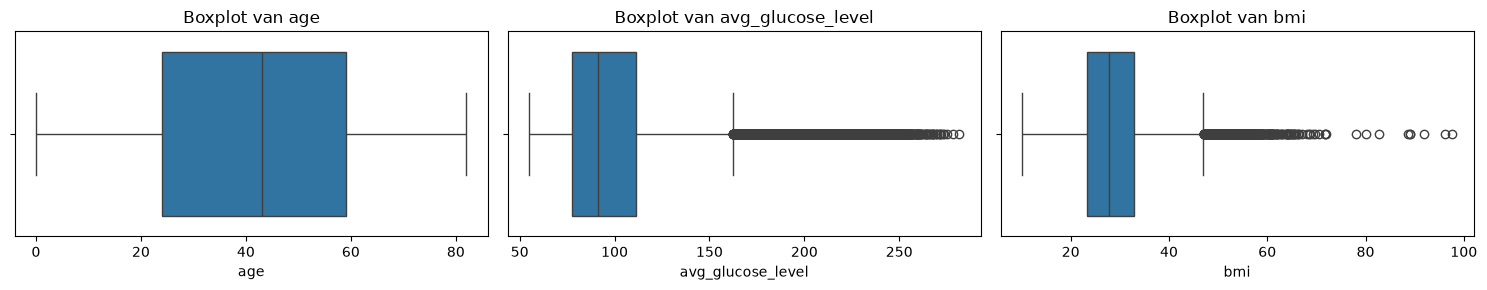

In [11]:
def plot_boxplots(df: pd.DataFrame, cols: list[str]) -> None:
    """Toon per numerieke kolom een boxplot om uitschieters te laten zien."""
    # Eén rij met een boxplot per kolom
    fig, axes = plt.subplots(1, len(cols), figsize=(15, 3))
    for ax, col in zip(axes, cols):
        # De losse rondjes in de boxplot zijn de uitschieters
        sns.boxplot(x=df[col], ax=ax)
        ax.set_title(f"Boxplot van {col}")
    plt.tight_layout()
    plt.show()


plot_boxplots(train_df, NUMERIC_COLS)

Observaties:
- **`age`** heeft **geen uitschieters**: alle leeftijden (0–82 jaar) liggen binnen de snorharen.
- **`avg_glucose_level`** heeft **veel uitschieters** boven ±162 mg/dL. Ze vormen een dikke zwarte balk tot 282 mg/dL. Dit zijn geen meetfouten, maar patiënten met een hoge bloedsuiker (bijv. diabetes).
- **`bmi`** heeft **uitschieters** boven ±47, met enkele extremen tussen 80 en 98. Zeldzaam, maar medisch mogelijk.
- **Conclusie:** we **behouden alle uitschieters**, omdat ze realistisch zijn en ook in de testset voorkomen.

### 4.4 Relaties tussen features en target

#### 4.4.1 Numerieke features

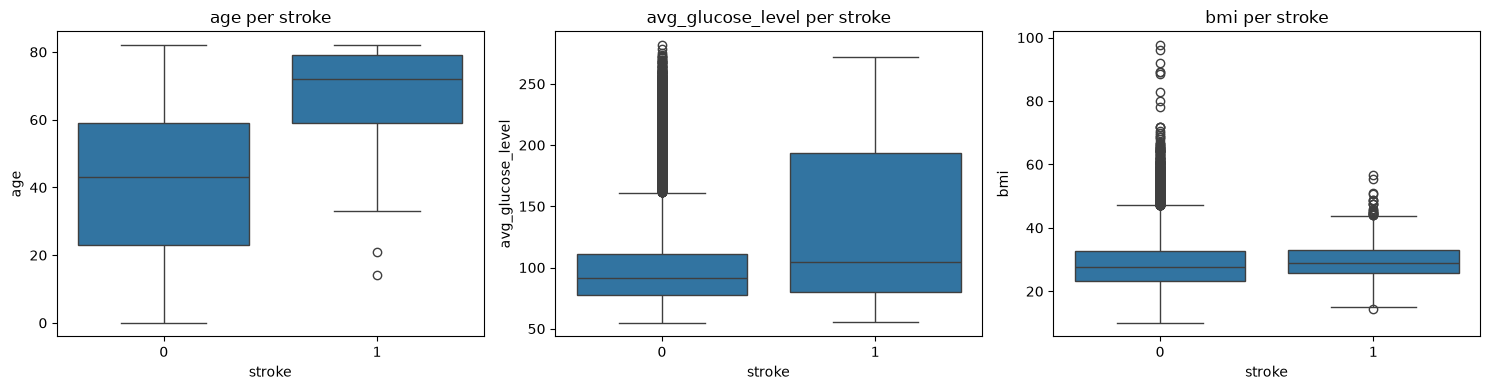

In [12]:
def plot_boxplot_per_stroke(df: pd.DataFrame, cols: list[str]) -> None:
    """Toon per numerieke feature een boxplot voor stroke = 0 en 1."""
    fig, axes = plt.subplots(1, len(cols), figsize=(15, 4))
    for ax, col in zip(axes, cols):
        # Vergelijk de waarden van patiënten zonder (0) en met (1) stroke
        sns.boxplot(data=df, x="stroke", y=col, ax=ax)
        ax.set_title(f"{col} per stroke")
    plt.tight_layout()
    plt.show()


plot_boxplot_per_stroke(train_df, NUMERIC_COLS)

**Observaties:**
- **`age`** heeft de duidelijkste relatie met `stroke`. De mediane leeftijd van patiënten met een herseninfarct is 72 jaar, tegenover 43 jaar bij patiënten zonder. Onder de 40 jaar komt een herseninfarct nauwelijks voor (alleen twee uitzonderingen rond 15 en 20 jaar).
- **`avg_glucose_level`** ligt hoger bij patiënten met een herseninfarct. Hun doos loopt door tot ongeveer 190 mg/dL, tegenover ongeveer 110 mg/dL bij patiënten zonder. De hoge waarden die voor de hele groep uitschieters zijn, zijn bij stroke-patiënten juist normaal. Een hoge bloedsuiker hangt dus samen met een verhoogd risico.
- **`bmi`** verschilt nauwelijks tussen beide groepen: de dozen liggen bijna op dezelfde hoogte. De extreme waarden (bmi > 60) komen alleen voor bij patiënten zonder herseninfarct.


#### 4.4.2 Binaire features

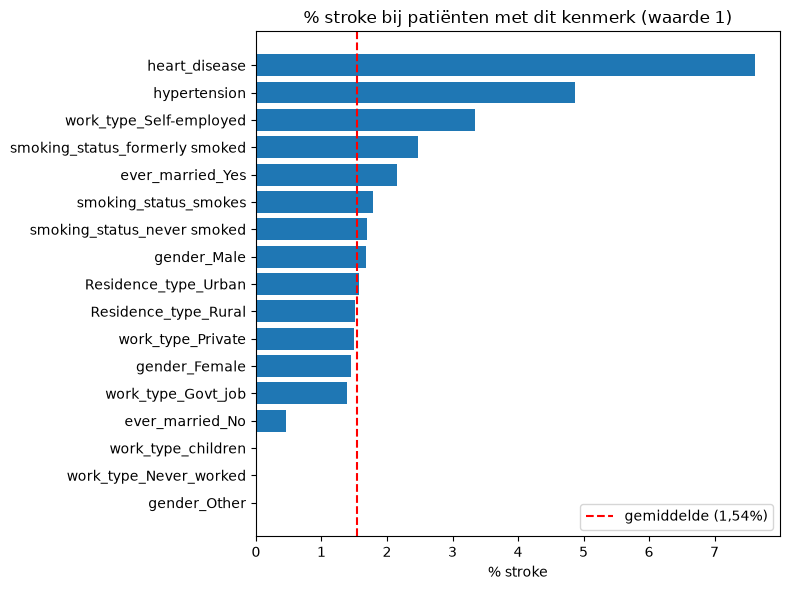

In [13]:
def plot_stroke_rate(df: pd.DataFrame, cols: list[str]) -> None:
    """Toon per binaire feature het % stroke bij patiënten met waarde 1."""
    # % stroke binnen de groep met waarde 1, gesorteerd van laag naar hoog
    rates = {col: df.loc[df[col] == 1, "stroke"].mean() * 100
             for col in cols}
    rates = pd.Series(rates).sort_values()

    plt.figure(figsize=(8, 6))
    plt.barh(rates.index, rates.values)
    # Rode stippellijn: gemiddelde % stroke van alle patiënten
    plt.axvline(df["stroke"].mean() * 100, color="red", linestyle="--",
                label="gemiddelde (1,54%)")
    plt.xlabel("% stroke")
    plt.title("% stroke bij patiënten met dit kenmerk (waarde 1)")
    plt.legend()
    plt.tight_layout()
    plt.show()


BINARY_COLS = [col for col in train_df.columns
               if col not in ["id", "stroke"] + NUMERIC_COLS]
plot_stroke_rate(train_df, BINARY_COLS)

**Observaties:**
- **`heart_disease`** en **`hypertension`** hebben de sterkste relatie met `stroke`: bij patiënten met een hartziekte is het percentage herseninfarcten ongeveer 6 keer zo hoog (7,6% vs. 1,25%), bij hoge bloeddruk ongeveer 4 keer zo hoog (4,9% vs. 1,2%).
- **`ever_married_Yes`**, **`work_type_Self-employed`** en **`smoking_status_formerly smoked`** laten een verhoogd percentage zien, terwijl **`work_type_children`** bijna geen herseninfarcten heeft. Dit wordt waarschijnlijk (deels) verklaard door **leeftijd**: getrouwde, zelfstandige en voormalige rokers zijn gemiddeld ouder. Leeftijd is hier een *confounder*.
- **`gender`**, **`Residence_type`**, **`work_type_Govt_job`**, **`work_type_Private`** en de overige rookcategorieën laten nauwelijks verschil zien.
- **`gender_Other`** en **`work_type_Never_worked`** bevatten geen enkele patiënt met een herseninfarct, omdat deze groepen erg klein zijn.

### 4.5 Correlaties
We berekenen voor iedere feature de correlatie met `stroke` met de functie `.corr()` van pandas (Pearson). Een correlatie ligt tussen −1 en 1:
- **positief**: hoe hoger de feature, hoe vaker een herseninfarct;
- **negatief**: hoe hoger de feature, hoe minder vaak een herseninfarct;
- **dicht bij 0**: (bijna) geen lineair verband.

#### 4.5.1 Correlatie met de target

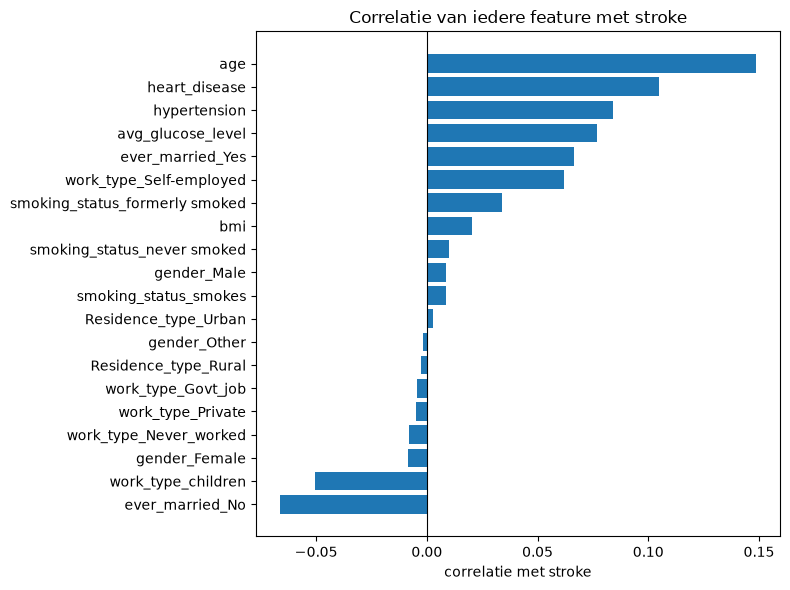

In [14]:
def plot_target_correlation(df: pd.DataFrame, target: str) -> None:
    """Toon de correlatie van iedere feature met de target."""
    # Correlatie van alle kolommen met de target (id telt niet mee)
    corr = df.drop(columns="id").corr()[target]
    # De target zelf weghalen (altijd 1) en sorteren
    corr = corr.drop(target).sort_values()

    plt.figure(figsize=(8, 6))
    plt.barh(corr.index, corr.values)
    plt.axvline(0, color="black", linewidth=0.8)
    plt.xlabel("correlatie met stroke")
    plt.title("Correlatie van iedere feature met stroke")
    plt.tight_layout()
    plt.show()


plot_target_correlation(train_df, target="stroke")

**Observaties:**
- De sterkste correlaties met `stroke` zijn **`age`** (0,15), **`heart_disease`** (0,11), **`hypertension`** (0,08) en **`avg_glucose_level`** (0,08). 
- **`ever_married_No`** en **`work_type_children`** hebben een negatieve correlatie: deze groepen bestaan vooral uit jonge patiënten en hebben dus minder vaak een herseninfarct.
- **`gender`**, **`Residence_type`** en **`bmi`** hebben een correlatie van bijna 0: (bijna) geen verband met `stroke`.
- **Alle correlaties zijn laag (≤ 0,15).** Dat komt deels doordat maar 1,54% van de patiënten een herseninfarct heeft. Een lage correlatie betekent niet dat een feature nutteloos is: correlatie meet alleen een **lineair** verband, terwijl modellen zoals een decision tree ook andere verbanden kunnen gebruiken.

#### 4.5.2 Correlatie tussen de features
Naast de correlatie met de target bekijken we hoe de features onderling samenhangen. Sterk gecorreleerde features bevatten deels dezelfde informatie: dit heet multicollineariteit en kan vooral lineaire modellen zoals logistic regression instabiel maken.

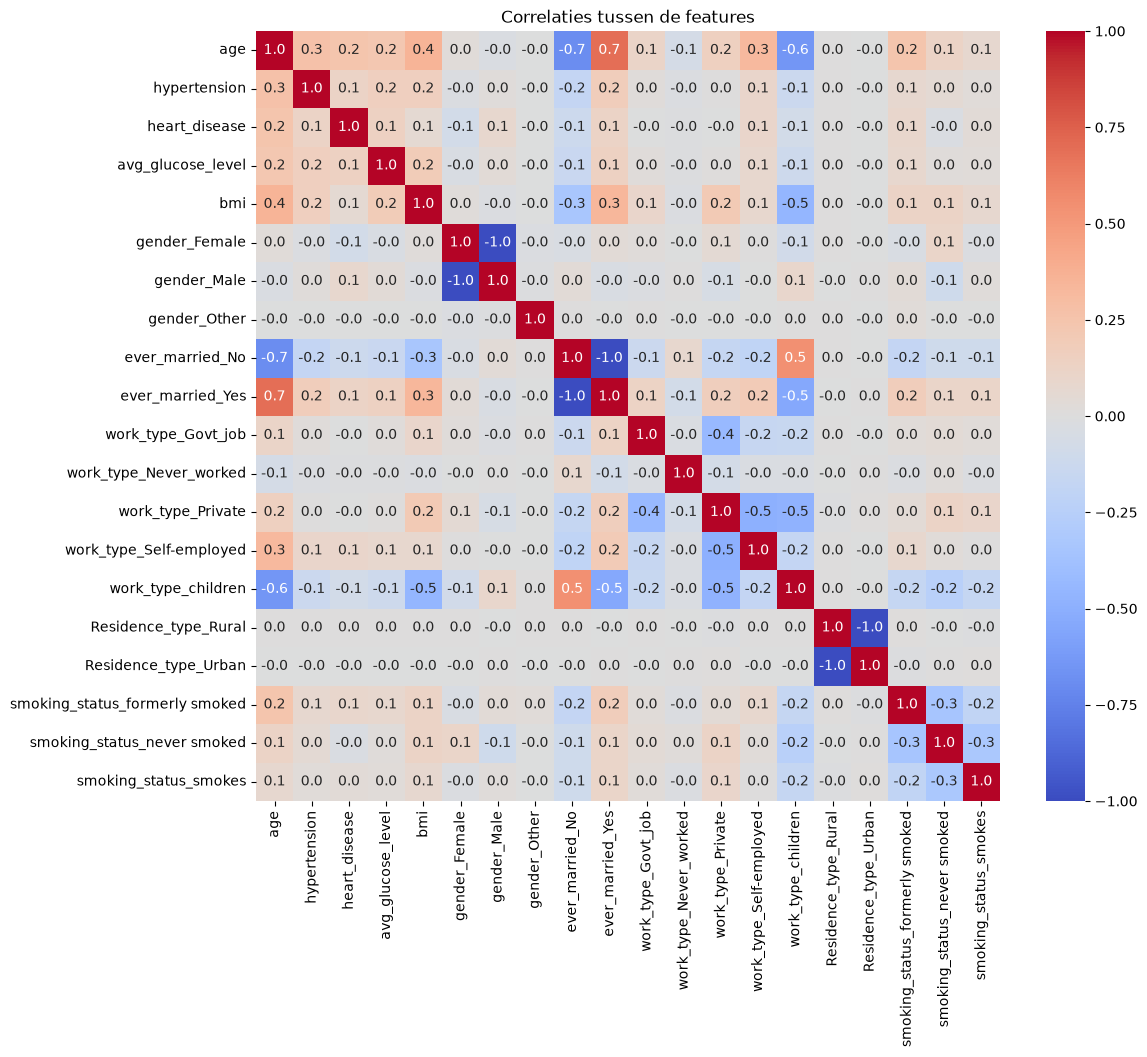

In [15]:
# Correlaties tussen alle features (id en target tellen niet mee)
corr = train_df.drop(columns=["id", "stroke"]).corr()

# Heatmap: rood = positief verband, blauw = negatief, wit = geen verband
plt.figure(figsize=(12, 10))
sns.heatmap(corr, cmap="coolwarm", annot=True, fmt=".1f")
plt.title("Correlaties tussen de features")
plt.show()

**Observaties:**
- **Dummy-paren** (bijv. `ever_married_No`/`_Yes`) hebben een correlatie van **−1,0**: ze bevatten dezelfde informatie. Daarom verwijderen we één kolom per paar (4.7).
- **`age`** hangt sterk samen met `ever_married_Yes` (**0,7**) en `work_type_children` (**−0,6**). Het verband van deze kenmerken met stroke (4.4.2) komt dus grotendeels door **leeftijd**.
- De overige correlaties tussen de features zijn laag.

### 4.6 Belangrijkste bevindingen

1. **Sterk onevenwichtige target:** slechts 1,54% van de patiënten heeft een herseninfarct gehad. Een model dat altijd 'geen stroke' voorspelt, haalt al 98,5% accuracy, maar vindt geen enkele patiënt.
2. **Leeftijd is de belangrijkste voorspeller:** herseninfarcten komen vrijwel alleen voor bij patiënten ouder dan 40 jaar (mediaan 72 tegenover 43 jaar).
3. **Medische factoren:** `heart_disease`, `hypertension` en een hoge `avg_glucose_level` verhogen het risico duidelijk.
4. **Leeftijd als confounder:** `age` hangt sterk samen met `ever_married_Yes` (0,7) en `work_type_children` (−0,6) (zie 4.5.2). Het hogere of lagere risico bij deze groepen komt dus grotendeels door leeftijd.
5. **Zwakke features:** `gender`, `Residence_type` en `bmi` hebben nauwelijks een relatie met `stroke`.
6. **Datakwaliteit:** geen ontbrekende waarden en geen duplicaten. Wel is bij 30,8% de rookstatus onbekend, en zijn er realistische uitschieters in `avg_glucose_level` en `bmi` (tot 97,6). Deze behouden we.
7. **Zeer kleine groepen:** `gender_Other` (6 patiënten) en `work_type_Never_worked` (141 patiënten) zijn te klein om betrouwbaar iets van te leren.
8. **Redundante kolommen:** een aantal dummy-paren (bijv. `ever_married_No` / `_Yes`) bevat dezelfde informatie. Per paar verwijderen we er één (4.6).
9. **Verschillende schalen:** `age` loopt tot 82, `avg_glucose_level` tot 282 en `bmi` tot 98. Daarom onderzoeken we standaardisatie (4.7).

### 4.7 Data opschonen

Op basis van de EDA voeren we de volgende stappen uit:
1. **`id` verwijderen uit de features.** Dit is een willekeurig nummer zonder relatie met `stroke`. De id's van de testset bewaren we apart voor de Kaggle-submission.
2. **Patiënten met `gender_Other` verwijderen uit de trainset.** Deze groep bevat slechts 6 patiënten, te weinig om iets van te leren. Daarna bevat de kolom alleen nog nullen en wordt ze verwijderd. Uit de testset verwijderen we geen rijen, omdat Kaggle voor elke patiënt een voorspelling verwacht.
3. **Eén dummy per categorische variabele verwijderen.** Deze is volledig af te leiden uit de andere kolommen. Dit voorkomt perfecte multicollineariteit, wat vooral van belang is voor lineaire modellen zoals logistic regression. We verwijderen `gender_Female`, `ever_married_No`, `Residence_type_Rural` en `work_type_Never_worked` (de kleinste groep, 141 patiënten). Bij roken is dit niet nodig: de categorie *Unknown* heeft al geen eigen kolom.
4. **Onbekende rookstatus behouden** als aparte categorie (alle rookkolommen 0). Verwijderen zou 30,8% van de data kosten.
5. **Uitschieters in `avg_glucose_level` en `bmi` behouden.** Ze zijn zeldzaam, maar medisch realistisch en komen ook in de testset voor. Door ze te behouden leert het model ook met deze patiënten omgaan.
6. **Jonge kinderen behouden.** Een leeftijd van 0,08 jaar is realistisch (baby's) en deze groep komt ook in de testset voor.

In [16]:
# Kolommen die we verwijderen: id (geen betekenis), gender_Other (te kleine
# groep) en per categorische variabele één overbodige dummy
DROP_COLS = [
    "id",
    "gender_Other",
    "gender_Female",
    "ever_married_No",
    "work_type_Never_worked",
    "Residence_type_Rural",
]


def clean_data(train: pd.DataFrame, test: pd.DataFrame
               ) -> tuple[pd.DataFrame, pd.DataFrame, pd.Series]:
    """Verwijder irrelevante rijen en kolommen uit de train- en testset."""
    # Bewaar de test-id's voor het inleverbestand van Kaggle
    test_ids = test["id"].copy()
    # Alleen in train: verwijder de 6 patiënten met gender_Other
    train = train[train["gender_Other"] == 0].copy()
    # Verwijder dezelfde kolommen uit train en test
    train = train.drop(columns=DROP_COLS)
    test = test.drop(columns=DROP_COLS)
    return train, test, test_ids


train_clean, test_clean, test_ids = clean_data(train_df, test_df)
print("Train:", train_clean.shape)
print("Test:", test_clean.shape)
print("Kolommen:", list(train_clean.columns))

Train: (33544, 16)
Test: (8388, 15)
Kolommen: ['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi', 'gender_Male', 'ever_married_Yes', 'work_type_Govt_job', 'work_type_Private', 'work_type_Self-employed', 'work_type_children', 'Residence_type_Urban', 'smoking_status_formerly smoked', 'smoking_status_never smoked', 'smoking_status_smokes', 'stroke']


**Resultaat:**
- **Train:** van 33.550 naar **33.544 rijen** (6 patiënten met `gender_Other` verwijderd) en van 22 naar **16 kolommen** (15 features + `stroke`).
- **Test:** het aantal rijen blijft **8.388**; van 21 naar **15 kolommen**. Train en test hebben dus dezelfde 15 features.
- De ene patiënt met `gender_Other` in de testset heeft na het verwijderen van de kolommen de waarde `gender_Male = 0` en wordt door het model dus als vrouw behandeld. Omdat het om slechts één patiënt gaat, heeft dit nauwelijks invloed op de resultaten.

**Features en target**

We splitsen de opgeschoonde trainset in de features `X` en de target `y`. Deze gebruiken we in de volgende hoofdstukken. `X_test` bevat de features van de testset voor de Kaggle-submission.

In [17]:
X = train_clean.drop(columns=TARGET)
y = train_clean[TARGET]
X_test = test_clean

print("X:", X.shape)
print("y:", y.shape)
print("X_test:", X_test.shape)

X: (33544, 15)
y: (33544,)
X_test: (8388, 15)


### 4.8 Standaardisatie

**Wat is standaardiseren?**
Bij standaardiseren zetten we elke numerieke feature om naar een schaal met gemiddelde 0 en standaardafwijking 1:

$$z = \frac{x - \mu}{\sigma}$$

waarbij $\mu$ het gemiddelde en $\sigma$ de standaardafwijking van de feature is. Een waarde van $z = 2$ betekent dus: twee standaardafwijkingen boven het gemiddelde.

**Wanneer is dit gewenst?**
- Bij modellen die met **afstanden** werken, zoals **K-Nearest Neighbors** en **SVM**. Zonder standaardisatie domineert de feature met de grootste getallen de afstand.
- Bij modellen die met **gradient descent** en **regularisatie** werken, zoals **logistic regression**. Standaardisatie zorgt dat het algoritme sneller convergeert en dat de regularisatie alle features even zwaar straft.
- **Niet nodig** bij **decision trees** en ensembles daarvan (random forest, gradient boosting). Deze splitsen op één feature tegelijk, waardoor de schaal geen invloed heeft.

**Voegt het waarde toe voor deze dataset?**
Ja. De numerieke features hebben sterk verschillende schalen: `age` loopt van 0 tot 82, `avg_glucose_level` van 55 tot 282 en `bmi` van 10 tot 98. Zonder standaardisatie zou `avg_glucose_level` bij KNN en SVM onterecht zwaarder wegen.

We standaardiseren alleen de numerieke features. De binaire features (0/1) laten we ongewijzigd, zodat hun betekenis behouden blijft.

**Let op:** de `StandardScaler` wordt alleen op de trainingsdata gefit en daarna toegepast op de validatie- en testdata. Zo lekt er geen informatie uit de test naar het model (*data leakage*). 



Hieronder tonen we het gemiddelde en de standaardafwijking van de numerieke features voor en na standaardisatie.

In [18]:
# Standaardiseer de kolommen: (x - gemiddelde) / standaardafwijking
def show_standardization(df: pd.DataFrame, cols: list[str]) -> pd.DataFrame:
    """Toon gemiddelde en standaardafwijking voor en na standaardisatie."""
     # Standaardiseer de kolommen: (x - gemiddelde) / standaardafwijking
    scaled = StandardScaler().fit_transform(df[cols])
    # fit_transform geeft een array terug; zet die om naar een DataFrame
    scaled_df = pd.DataFrame(scaled, columns=cols)
    # Vergelijk gemiddelde en standaardafwijking voor en na
    return pd.DataFrame({
        "gemiddelde_voor": df[cols].mean(),
        "std_voor": df[cols].std(),
        "gemiddelde_na": scaled_df.mean().values,
        "std_na": scaled_df.std().values,
    }).round(2)


show_standardization(train_clean, NUMERIC_COLS)

,gemiddelde_voor,std_voor,gemiddelde_na,std_na
age,41.82,22.48,-0.0,1.0
avg_glucose_level,103.59,42.13,0.0,1.0
bmi,28.60,7.78,0.0,1.0


**Conclusie:** na standaardisatie hebben alle drie de numerieke features een gemiddelde van 0 en een standaardafwijking van 1. Ze liggen nu op dezelfde schaal en wegen daardoor even zwaar mee bij modellen die met afstanden of gradient descent werken. (De waarde -0,0 is het gevolg van afronding van een zeer klein getal en is in feite 0.)

------
## 5. Evaluatie

In dit hoofdstuk bepalen we met welke metrics we kunnen meten hoe goed een model presteert. We laten de uitkomsten zien met een eenvoudig model en leggen uit hoe iedere metric wordt berekend.

### 5.1 Train- en validatieset
De testset van Kaggle bevat geen `stroke`-kolom, dus daarmee kunnen we zelf niet controleren hoe goed een model is. Daarom splitsen we de opgeschoonde trainset in een trainset (80%) om het model op te trainen en een validatieset (20%) om het te testen op patiënten die het model nog niet heeft gezien.

We gebruiken `stratify=y`, zodat beide sets hetzelfde percentage stroke-patiënten (1,54%) bevatten. Zonder stratificatie zouden er door toeval te weinig stroke-patiënten in de validatieset kunnen komen.

In [19]:
# 80% train, 20% validatie; stratify zorgt voor 1,54% stroke in beide sets
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print("Train:", X_train.shape, "| stroke-patiënten:", y_train.sum())
print("Validatie:", X_val.shape, "| stroke-patiënten:", y_val.sum())

Train: (26835, 15) | stroke-patiënten: 414
Validatie: (6709, 15) | stroke-patiënten: 103


**Observatie:** de trainset bevat 26.835 patiënten (414 met stroke) en de validatieset 6.709 patiënten (103 met stroke). In beide sets is het aandeel stroke-patiënten 1,54%, gelijk aan de volledige dataset.


### 5.2 Metrics voor binaire classificatie
Bij binaire classificatie (stroke ja/nee) kunnen we met de volgende metrics bepalen hoe goed een model presteert:
- **Accuracy**
- **Precision**
- **Recall**
- **F1-score**

In 5.4 leggen we met een confusion matrix uit hoe iedere metric wordt berekend.

### 5.3 Gekozen model en uitkomsten
Om de metrics te demonstreren, gebruiken we **logistic regression**: een eenvoudig model voor binaire classificatie. We trainen het model bewust zonder technieken voor imbalanced data, zodat we zien hoe de metrics zich gedragen bij een standaardmodel.

We gebruiken een pipeline: eerst worden de features gestandaardiseerd zie 4.8, daarna wordt het model getraind. De StandardScaler wordt zo alleen op de trainset gefit, waardoor er geen informatie uit de validatieset lekt (data leakage).

In [20]:
# Pipeline: eerst standaardiseren, dan logistic regression
model = Pipeline([
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])

# Train het model en voorspel de validatieset
model.fit(X_train, y_train)
y_pred = model.predict(X_val)

# Bereken de vier metrics
scores = pd.Series({
    "accuracy": accuracy_score(y_val, y_pred),
    "precision": precision_score(y_val, y_pred, zero_division=0),
    "recall": recall_score(y_val, y_pred),
    "f1": f1_score(y_val, y_pred),
}).round(3)

print("Aantal voorspellingen per klasse:",
      pd.Series(y_pred).value_counts().to_dict())
scores

Aantal voorspellingen per klasse: {0: 6709}


accuracy     0.985
precision    0.000
recall       0.000
f1           0.000
dtype: float64

**Observaties:**
- Het model voorspelt voor alle 6.709 patiënten "geen stroke". Doordat maar 1,54% van de patiënten een herseninfarct heeft, leert het model dat "altijd 0 zeggen" bijna altijd goed is.
- De accuracy is 0,985 (98,5%): dat lijkt uitstekend.
- Maar precision, recall en F1 zijn 0: het model vindt geen enkele van de 103 patiënten met een herseninfarct.
- Accuracy geeft hier dus een misleidend beeld. In 5.4 laten we met de confusion matrix zien hoe dit komt.

### 5.4 Confusion matrix en berekening van de metrics
Een **confusion matrix** zet de echte waarden tegenover de voorspellingen van het model. Zo zien we niet alleen hoeveel voorspellingen goed zijn, maar ook welke soort fouten het model maakt:

| | **Voorspeld: geen stroke (0)** | **Voorspeld: stroke (1)** |
|---|---|---|
| **Echt: geen stroke (0)** | **TN** – True Negative | **FP** – False Positive |
| **Echt: stroke (1)** | **FN** – False Negative | **TP** – True Positive |



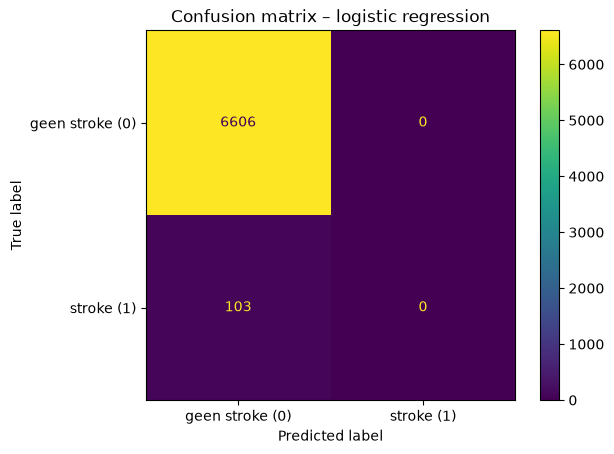

TN: 6606 | FP: 0 | FN: 103 | TP: 0


In [21]:
# Confusion matrix als grafiek
ConfusionMatrixDisplay.from_predictions(
    y_val, y_pred, display_labels=["geen stroke (0)", "stroke (1)"]
)
plt.title("Confusion matrix – logistic regression")
plt.show()

# De vier vakjes los uitlezen: ravel() zet de 2x2-tabel op één rij
tn, fp, fn, tp = confusion_matrix(y_val, y_pred).ravel()
print("TN:", tn, "| FP:", fp, "| FN:", fn, "| TP:", tp)

**Observaties:**
- **TN = 6.606:** alle patiënten zonder herseninfarct worden correct als "geen stroke" voorspeld.
- **FP = 0:** het model geeft nooit vals alarm, maar dat komt doordat het nooit "stroke" voorspelt.
- **FN = 103:** **alle** 103 patiënten met een herseninfarct worden gemist. 
- **TP = 0:** het model vindt geen enkele patiënt met een herseninfarct.

#### Berekening van de metrics
Met de getallen uit de confusion matrix (TN = 6.606, FP = 0, FN = 103, TP = 0) berekenen we iedere metric:

**Accuracy**: welk deel van alle voorspellingen is goed?
$$\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN} = \frac{0 + 6606}{6709} = 0{,}985$$

**Precision**: van alle patiënten die het model als "stroke" aanwijst, hoeveel hebben echt een herseninfarct gehad?
$$\text{Precision} = \frac{TP}{TP + FP} = \frac{0}{0 + 0}$$
Delen door 0 kan niet, omdat het model nooit "stroke" voorspelt. Scikit-learn geeft dan 0.

**Recall**: van alle patiënten die echt een herseninfarct hebben gehad, hoeveel vindt het model?
$$\text{Recall} = \frac{TP}{TP + FN} = \frac{0}{0 + 103} = 0$$

**F1-score**: combineert precision en recall in één getal.
$$F1 = 2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}} = 2 \cdot \frac{0 \cdot 0}{0 + 0} = 0$$

**Conclusie:** de handmatige berekeningen geven dezelfde uitkomsten als scikit-learn in 5.3. De accuracy is hoog (98,5%) doordat bijna alle patiënten in de grootste klasse (geen stroke) zitten. Precision, recall en F1 kijken juist naar de stroke-patiënten en laten zien dat het model hier niets waard is.

#### Vergelijking: een model dat altijd "stroke" voorspelt
Onze logistic regression voorspelt bij niemand "stroke". Om te zien hoe de metrics reageren op het tegenovergestelde, berekenen we ze ook voor een "dom" model dat bij iedere patiënt "stroke" voorspelt. Dit model gebruikt geen enkele feature; het is alleen bedoeld als vergelijking.

In [22]:
# Een "dom" model dat bij iedereen stroke (1) voorspelt
y_pred_alles_1 = [1] * len(y_val)

print("Accuracy: ", round(accuracy_score(y_val, y_pred_alles_1), 3))
print("Precision:", round(precision_score(y_val, y_pred_alles_1), 3))
print("Recall:   ", round(recall_score(y_val, y_pred_alles_1), 3))
print("F1:       ", round(f1_score(y_val, y_pred_alles_1), 3))

Accuracy:  0.015
Precision: 0.015
Recall:    1.0
F1:        0.03


Samen met de logistic regression hebben we nu twee waardeloze modellen:

| Model | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|
| Logistic regression (altijd "geen stroke") | 0,985 | 0 | 0 | **0** |
| Altijd "stroke" | 0,015 | 0,015 | 1,0 | **0,03** |

### 5.5 Waarom de F1-score?
Kaggle beoordeelt de modellen met de F1-score. De twee modellen hierboven laten zien waarom dit voor dit vraagstuk de beste maatstaf is:

**1. Accuracy is misleidend bij imbalanced data.**
De logistic regression haalt 98,5% accuracy, terwijl het geen enkele stroke-patiënt vindt. Dat komt doordat accuracy ook de 6.606 True Negatives meetelt: de grote groep gezonde patiënten. Omdat maar 1,54% een herseninfarct heeft, scoort "altijd nee zeggen" al bijna perfect.

**2. Recall alleen is ook niet genoeg.**
Het model dat altijd "stroke" voorspelt, heeft een perfecte recall (1,0), maar 6.606 van de 6.709 meldingen zijn vals alarm. Voor artsen is zo'n model net zo onbruikbaar.

**3. De F1-score combineert precision en recall.**
De F1-score wordt laag zodra precision **of** recall laag is. Een model scoort dus alleen hoog als het zowel veel stroke-patiënten vindt (weinig FN) als weinig vals alarm geeft (weinig FP). Beide waardeloze modellen hierboven krijgen daarom terecht een F1-score van (bijna) 0.

**4. De F1-score kijkt naar de stroke-patiënten.**
De F1-score gebruikt alleen TP, FP en FN, en geen TN. De grote groep gezonde patiënten kan de score dus niet kunstmatig hoog maken, zoals bij accuracy gebeurt.

**Kanttekening:** in deze medische toepassing is een gemiste patiënt (FN) erger dan een vals alarm (FP). De F1-score weegt precision en recall even zwaar.

### 5.6 Conclusie
Voor binaire classificatie kunnen we een model beoordelen met accuracy, precision, recall en de F1-score. Omdat slechts 1,54% van de patiënten een herseninfarct heeft, is accuracy misleidend: een model dat nooit "stroke" voorspelt, haalt al 98,5%. De **F1-score** is voor dit vraagstuk de beste maatstaf, omdat hij alleen hoog is als het model zowel veel stroke-patiënten vindt als weinig vals alarm geeft. In hoofdstuk 6 gebruiken we daarom de F1-score om de modellen te vergelijken en af te stellen, en houden we daarnaast de recall in de gaten.

-----
## 6. Modelleren 

In dit hoofdstuk trainen we verschillende modellen om een herseninfarct te voorspellen. Per model leggen we uit hoe het werkt, welke keuzes we maken en wat de resultaten zijn. De modellen worden met elkaar vergeleken in hoofdstuk 7.

### 6.1 Imbalanced dataset en gebruikte technieken

**Het probleem**

Slechts 1,54% van de patiënten heeft een herseninfarct gehad (517 van de 33.544). In hoofdstuk 5 zagen we wat dit betekent: een model zonder aanpassingen voorspelt voor iedereen "geen stroke" en haalt daarmee 98,5% accuracy, maar vindt geen enkele patiënt. Voor het model is het negeren van de kleine klasse de makkelijkste manier om weinig fouten te maken.

**Gebruikte technieken**

1. **Class weights.** Met `class_weight="balanced"` telt een fout bij een patiënt met een herseninfarct zwaarder mee tijdens het trainen. Het gewicht is omgekeerd evenredig met de klassegrootte: een patiënt met een herseninfarct telt ongeveer 64 keer zo zwaar als een patiënt zonder. Bij XGBoost heet deze instelling `scale_pos_weight`.
2. **Threshold aanpassen.** Een model voorspelt een kans. Standaard wordt een patiënt als risicopatiënt aangewezen als deze kans ≥ 0,5 is. Deze grens (de threshold) kunnen we zelf kiezen. Met `TunedThresholdClassifierCV` zoeken we de threshold met de hoogste F1-score.

**Evaluatie met cross-validatie**

In hoofdstuk 5 gebruikten we één validatieset om de metrics uit te leggen. Die bevat maar 103 patiënten met een herseninfarct, waardoor de score sterk afhangt van welke patiënten toevallig in de validatieset zitten. Voor het vergelijken van modellen gebruiken we daarom **5-fold cross-validatie**: de data wordt in vijf delen gesplitst en elk deel is één keer validatieset. De score is het gemiddelde over de vijf folds.

- Met `StratifiedKFold` bevat elke fold hetzelfde percentage herseninfarcten (1,54%).
- Alle stappen die van de data leren (standaardiseren, threshold kiezen) gebeuren binnen elke fold alleen op de trainingsdata. Zo voorkomen we data leakage.
- We rapporteren accuracy, precision, recall en de F1-score. De F1-score is leidend (zie paragraaf 5.5).

In [23]:

# Prompt 1: Cross-validatie en scoring bij een ongebalanceerde dataset

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": "recall",
    "f1": "f1",
}

[ChatGPT, 2026, Prompt 1: Cross-validatie en scoring bij een ongebalanceerde dataset](https://chatgpt.com/share/6ac288d2-1638-83ed-a0f3-30b92d4f448a)

### 6.2 K-Nearest Neighbors

-----
### 6.3 Logistic Regression

**Wat is logistic regression?**
Logistic regression is een classificatiemodel. Het model berekent eerst een gewogen som van de features:

$$z = b_0 + b_1 x_1 + b_2 x_2 + \dots + b_n x_n$$

Deze som zet het model met de sigmoïdefunctie om naar een kans tussen 0 en 1:

$$P(\text{stroke} = 1) = \frac{1}{1 + e^{-z}}$$

Is de kans groter dan de threshold (standaard 0,5), dan voorspelt het model een herseninfarct.

**Waarom dit model?**
- Het is een eenvoudig en snel model, en daarom een goede baseline om andere modellen mee te vergelijken.
- De coëfficiënten zijn goed te interpreteren: een positieve coëfficiënt betekent dat de feature de kans op een herseninfarct verhoogt. Dat is belangrijk voor artsen, die willen begrijpen waarom het model een patiënt als risicopatiënt aanwijst.

#### Baseline

We beginnen met een logistic regression met standaardinstellingen. Dit dient als baseline: elk volgend model moet beter scoren.

- Alleen de numerieke features worden gestandaardiseerd (zie paragraaf 4.8). De binaire features blijven 0/1.
- De scaler zit in een `Pipeline`, zodat hij per fold alleen op de trainingsdata wordt gefit. Zo voorkomen we data leakage.
- We evalueren met 5-fold cross-validatie (zie paragraaf 6.1).

In [24]:
# Prompt 2: Logistic Regression pipeline zonder data leakage

preprocessor = ColumnTransformer(
    [("scale", StandardScaler(), NUMERIC_COLS)],
    remainder="passthrough",  # binaire kolommen blijven 0/1
)

baseline = Pipeline([
    ("pre", preprocessor),
    ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])

scores = cross_validate(baseline, X, y, cv=cv, scoring=scoring)
for metric in scoring:
    print(f"{metric}: {scores[f'test_{metric}'].mean():.3f}")

accuracy: 0.985
precision: 0.000
recall: 0.000
f1: 0.000


[ChatGPT, 2026, Prompt 2: Logistic Regression pipeline zonder data leakage](https://chatgpt.com/share/6ac288d2-1638-83ed-a0f3-30b92d4f448a)

**Observatie:** de baseline voorspelt voor geen enkele patiënt een herseninfarct. De accuracy is 0,985, maar dat is precies het percentage patiënten zonder herseninfarct. De recall en F1-score zijn 0: het model vindt geen enkele risicopatiënt en is daarmee voor een arts onbruikbaar. Door de sterke onbalans is het voor het model 'voordeliger' om de kleine klasse te negeren.

#### Class weights

Om de onbalans op te vangen gebruiken we `class_weight="balanced"` (zie paragraaf 6.1). Een fout bij een patiënt met een herseninfarct telt dan zwaarder mee in de loss dan een fout bij een patiënt zonder.

In [25]:
balanced = Pipeline([
    ("pre", preprocessor),
    ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE,
                               class_weight="balanced")),
])

scores = cross_validate(balanced, X, y, cv=cv, scoring=scoring)
for metric in scoring:
    print(f"{metric}: {scores[f'test_{metric}'].mean():.3f}")

accuracy: 0.748
precision: 0.047
recall: 0.803
f1: 0.089


**Observatie:** de recall stijgt van 0 naar 0,803: het model vindt nu 80% van de patiënten met een herseninfarct. De precision is echter slechts 0,047: van elke 100 patiënten die het model als risicopatiënt aanwijst, heeft maar ongeveer 5 daadwerkelijk een herseninfarct. De F1-score (0,089) is beter dan de baseline, maar nog laag. Het model is doorgeslagen naar de andere kant: het geeft te veel valse alarmen.

#### Confusion matrix

De scores hierboven zijn gemiddelden over de folds. Met een confusion matrix (zie paragraaf 5.4) zien we per patiënt wat het model voorspelt.

We gebruiken `cross_val_predict`: elke patiënt krijgt een voorspelling van het model dat níét op die patiënt is getraind. Zo bevat de matrix alle 33.544 patiënten zonder dat het model de antwoorden al heeft gezien.

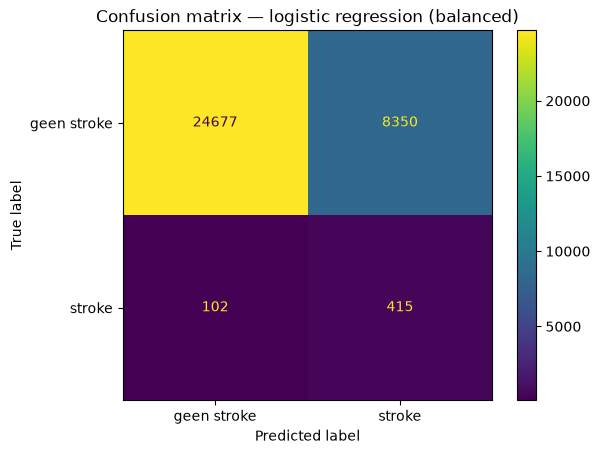

In [26]:
y_pred = cross_val_predict(balanced, X, y, cv=cv)

ConfusionMatrixDisplay.from_predictions(
    y, y_pred, display_labels=["geen stroke", "stroke"]
)
plt.title("Confusion matrix — logistic regression (balanced)")
plt.show()

**Observatie:** het model vindt 415 van de 517 patiënten met een herseninfarct (TP) en mist er 102 (FN). Daar staan 8.350 valse alarmen tegenover (FP): patiënten zonder herseninfarct die als risicopatiënt worden aangewezen. Voor een arts betekent dit dat ongeveer 95 van elke 100 waarschuwingen onterecht zijn. Het model is gevoelig, maar niet specifiek genoeg.

#### Threshold

Logistic regression voorspelt een kans. Standaard wordt een patiënt als risicopatiënt aangewezen als deze kans ≥ 0,5 is. Deze grens (de threshold) kunnen we zelf kiezen:

- Een **hogere** threshold geeft minder valse alarmen (hogere precision), maar het model mist meer patiënten met een herseninfarct (lagere recall).
- Een **lagere** threshold werkt andersom.

We bekijken de precision, recall en F1-score bij verschillende thresholds.

In [27]:
# Prompt 3: Threshold tuning voor Logistic Regression

y_proba = cross_val_predict(balanced, X, y, cv=cv, method="predict_proba")[:, 1]

rows = []
for threshold in np.arange(0.5, 1.0, 0.05):
    y_pred_t = (y_proba >= threshold).astype(int)
    rows.append({
        "threshold": round(threshold, 2),
        "precision": precision_score(y, y_pred_t, zero_division=0),
        "recall": recall_score(y, y_pred_t),
        "f1": f1_score(y, y_pred_t),
    })

pd.DataFrame(rows).round(3)

,threshold,precision,recall,f1
0,0.50,0.047,0.803,0.089
1,0.55,0.052,0.776,0.098
2,0.60,0.056,0.729,0.105
3,0.65,0.062,0.692,0.114
4,0.70,0.070,0.646,0.127
5,0.75,0.076,0.559,0.135
6,0.80,0.085,0.420,0.141
7,0.85,0.097,0.282,0.145
8,0.90,0.103,0.106,0.105
9,0.95,0.127,0.014,0.024


**Observatie:** hoe hoger de threshold, hoe hoger de precision en hoe lager de recall. De hoogste F1-score (0,145) ligt bij een threshold van 0,85, maar daar vindt het model nog maar 28% van de patiënten met een herseninfarct. Bij 0,80 is de F1-score bijna even hoog (0,141) met een recall van 42%. Zelfs bij de beste threshold blijft de precision onder de 10%. Het probleem zit dus niet alleen in de threshold: veel patiënten met dezelfde risicofactoren (hoge leeftijd, hoge bloeddruk) krijgen géén herseninfarct, waardoor het model de klassen moeilijk kan scheiden.

#### Threshold kiezen zonder data leakage

In de tabel hierboven hebben we de threshold gekozen op basis van dezelfde voorspellingen waarop we de score meten. Daardoor is de score te optimistisch. Met `TunedThresholdClassifierCV` wordt de threshold binnen elke fold alleen op de trainingsdata gekozen en daarna getest op data die het model niet heeft gezien.

In [28]:
# Prompt 3: Threshold tuning voor Logistic Regression


tuned = TunedThresholdClassifierCV(
    balanced, scoring="f1", cv=5, random_state=RANDOM_STATE
)

scores = cross_validate(tuned, X, y, cv=cv, scoring=scoring, return_estimator=True)
for metric in scoring:
    print(f"{metric}: {scores[f'test_{metric}'].mean():.3f}")

print("Gekozen thresholds:",
      [round(float(m.best_threshold_), 2) for m in scores["estimator"]])

accuracy: 0.924
precision: 0.087
recall: 0.412
f1: 0.143
Gekozen thresholds: [0.8, 0.81, 0.8, 0.81, 0.81]


[ChatGPT, 2026, Prompt 3: Threshold tuning voor Logistic Regression](https://chatgpt.com/share/6ac288d2-1638-83ed-a0f3-30b92d4f448a)

**Observatie:** met een eerlijk gekozen threshold is de F1-score 0,143. Dit ligt dicht bij de 0,145 uit de tabel hierboven, dus die schatting was nauwelijks te optimistisch. In alle vijf de folds wordt een threshold van 0,80 of 0,81 gekozen: de keuze is stabiel en niet afhankelijk van toeval. Het model vindt nu 41% van de patiënten met een herseninfarct, en ongeveer 9 van elke 100 waarschuwingen zijn terecht. Ten opzichte van `class_weight="balanced"` met threshold 0,5 levert dit een duidelijk betere balans tussen precision en recall op.

#### Hyperparameter tuning

Logistic regression gebruikt standaard L2-regularisatie. De sterkte hiervan bepalen we met de hyperparameter `C`. Een kleine `C` betekent sterke regularisatie (een eenvoudiger model met kleinere coëfficiënten), een grote `C` betekent zwakke regularisatie. We zoeken met `GridSearchCV` de beste waarde, waarbij voor elke `C` ook de threshold opnieuw wordt gekozen.

In [29]:
# Prompt 4: Hyperparameter tuning van Logistic Regression

param_grid = {"estimator__clf__C": [0.001, 0.01, 0.1, 1, 10]}

grid = GridSearchCV(tuned, param_grid, scoring="f1", cv=cv, n_jobs=-1)
grid.fit(X, y)

results = pd.DataFrame(grid.cv_results_)[
    ["param_estimator__clf__C", "mean_test_score", "std_test_score"]
]
results.columns = ["C", "f1_gemiddeld", "f1_std"]
print(results.round(3))
print("Beste C:", grid.best_params_["estimator__clf__C"])

        C  f1_gemiddeld  f1_std
0   0.001         0.137   0.010
1   0.010         0.141   0.008
2   0.100         0.142   0.009
3   1.000         0.143   0.008
4  10.000         0.143   0.008
Beste C: 1


[ChatGPT, 2026, Prompt 4: Hyperparameter tuning van Logistic Regression](https://chatgpt.com/share/6ac28d12-0404-83ed-9f48-af1214bd7174)

**Observatie:** de F1-score varieert tussen 0,137 en 0,143. Dit verschil (0,006) is kleiner dan de standaardafwijking tussen de folds (0,008–0,010) en dus niet betekenisvol. De sterkte van de regularisatie heeft nauwelijks invloed. Dit is te verklaren: met 33.544 patiënten en slechts 15 features heeft een lineair model weinig kans om te overfitten. We houden de standaardwaarde `C = 1` aan.

#### Interpretatie van het model

Een voordeel van logistic regression is dat de coëfficiënten te interpreteren zijn. We trainen het model op de volledige trainset en bekijken de odds ratio per feature: $e^{b}$.

- **Odds ratio > 1:** de feature verhoogt de kans op een herseninfarct.
- **Odds ratio < 1:** de feature verlaagt de kans.
- Voor de gestandaardiseerde features (`age`, `avg_glucose_level`, `bmi`) geldt de odds ratio per standaardafwijking. Voor de binaire features geldt deze ten opzichte van de weggelaten dummy (zie paragraaf 4.7).

In [30]:
final_model = Pipeline([
    ("pre", ColumnTransformer(
        [("scale", StandardScaler(), NUMERIC_COLS)],
        remainder="passthrough",
        verbose_feature_names_out=False,
    )),
    ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE,
                               class_weight="balanced")),
])
final_model.fit(X, y)

coefs = pd.DataFrame({
    "feature": final_model.named_steps["pre"].get_feature_names_out(),
    "coëfficiënt": final_model.named_steps["clf"].coef_[0],
})
coefs["odds_ratio"] = np.exp(coefs["coëfficiënt"])
coefs.sort_values("coëfficiënt", key=abs, ascending=False).round(2)

,feature,coëfficiënt,odds_ratio
0,age,1.72,5.58
4,heart_disease,0.62,1.86
3,hypertension,0.59,1.80
14,smoking_status_smokes,0.51,1.66
7,work_type_Govt_job,-0.40,0.67
10,work_type_children,-0.36,0.70
8,work_type_Private,-0.34,0.71
13,smoking_status_never smoked,0.23,1.26
9,work_type_Self-employed,-0.20,0.81
12,smoking_status_formerly smoked,0.20,1.22


**Observatie:**
- De drie sterkste voorspellers zijn `age`, `heart_disease` en `hypertension`, dezelfde features als in de EDA. Een standaardafwijking hogere leeftijd (ongeveer 22 jaar) vergroot de odds op een herseninfarct met een factor 5,6. Een hartziekte of hoge bloeddruk verdubbelt de odds ongeveer.
- `ever_married_Yes` heeft in de EDA een duidelijk verband met `stroke`, maar in het model is de odds ratio 0,92. Het model corrigeert voor leeftijd, waardoor dit verband verdwijnt. Dit bevestigt dat leeftijd een confounder is (paragraaf 4.5.2).
- `avg_glucose_level` heeft een kleiner effect (1,18) dan de EDA deed vermoeden. Het effect zit vooral in de zeer hoge waarden (zie paragraaf 4.4.1), terwijl logistic regression alleen een lineair verband kan leggen.
- De coëfficiënten van `work_type` zijn niet goed te interpreteren: ze zijn relatief ten opzichte van `work_type_Never_worked`, een zeer kleine groep zonder herseninfarcten.
- Alle rookcategorieën hebben een odds ratio > 1, omdat ze vergeleken worden met de categorie Unknown, waarin veel kinderen zitten. Dit betekent niet dat niet-roken het risico verhoogt.

**Voor de arts:** het model baseert zijn voorspellingen vooral op bekende medische risicofactoren. Dit maakt de voorspellingen goed uitlegbaar.

#### Kaggle-submission

Het uiteindelijke model is logistic regression met `class_weight="balanced"`, `C = 1` en een threshold die met `TunedThresholdClassifierCV` wordt gekozen. We trainen dit model op de volledige trainset en voorspellen de testset.

In [31]:
final_tuned = TunedThresholdClassifierCV(
    balanced, scoring="f1", cv=5, random_state=RANDOM_STATE
)
final_tuned.fit(X, y)

test_pred = final_tuned.predict(X_test)

submission = pd.DataFrame({"id": test_ids, TARGET: test_pred})
SUBMISSION_DIR.mkdir(exist_ok=True)
submission.to_csv(SUBMISSION_DIR / "logreg.csv", index=False)

print("Gekozen threshold:", round(float(final_tuned.best_threshold_), 2))
print("Aantal voorspelde herseninfarcten:", test_pred.sum(),
      f"({test_pred.mean() * 100:.2f}%)")

Gekozen threshold: 0.8
Aantal voorspelde herseninfarcten: 664 (7.92%)


**Observatie:** op de volledige trainset wordt opnieuw een threshold van 0,80 gekozen, gelijk aan de cross-validatie. Het model wijst 664 van de 8.388 testpatiënten (7,92%) aan als risicopatiënt. Als de testset hetzelfde percentage herseninfarcten heeft als de trainset (1,54%, ongeveer 129 patiënten), zijn de meeste waarschuwingen vals alarm. Dit komt overeen met de precision van ongeveer 9% uit de cross-validatie.

#### Conclusie logistic regression

| Model | Precision | Recall | F1-score |
|---|---|---|---|
| Baseline | 0,000 | 0,000 | 0,000 |
| `class_weight="balanced"` (threshold 0,5) | 0,047 | 0,803 | 0,089 |
| `class_weight="balanced"` + getunede threshold | 0,087 | 0,412 | **0,143** |

- Zonder aanpassingen negeert logistic regression de kleine klasse volledig. Class weights en een getunede threshold zijn allebei nodig voor een bruikbaar model.
- Het beste model vindt 41% van de patiënten met een herseninfarct. Ongeveer 9 van elke 100 waarschuwingen zijn terecht.
- De regularisatiesterkte `C` heeft nauwelijks invloed, omdat een lineair model met 15 features op 33.544 patiënten weinig overfit.
- **Sterk punt:** het model is goed uitlegbaar. De belangrijkste voorspellers (leeftijd, hartziekte en hoge bloeddruk) zijn bekende medische risicofactoren.
- **Zwak punt:** het model kan alleen lineaire verbanden leggen. Het niet-lineaire effect van `avg_glucose_level` (vooral bij zeer hoge waarden) wordt daardoor gemist. Modellen op basis van decision trees kunnen dit wel oppikken (zie paragraaf 6.5 en 6.6).

### 6.4 Support Vector Machine

#### Theorie: hoe werkt een SVM?

Een Support Vector Machine probeert een scheidingslijn, vlak of hypervlak te vinden dat de klassen zo goed mogelijk van elkaar scheidt. Bij binaire classificatie zoekt SVM een grens tussen klasse `0` en klasse `1`. De punten die het dichtst bij deze grens liggen, heten **support vectors**. Deze punten bepalen voor een groot deel waar de grens komt te liggen (OpenAI, 2026, prompt 1: SVM theorie en begrippen).

Bij een lineaire SVM kan de beslisfunctie worden geschreven als:

$$
f(x) = w^T x + b
$$

Daarbij is:
- $x$ de invoer met kenmerken van een patiënt;
- $w$ de vector met gewichten;
- $b$ de bias/intercept;
- $f(x)$ de score waarmee wordt bepaald aan welke kant van de grens een patiënt valt.

De hyperparameter `C` bepaalt hoe streng het model fouten bestraft:
- lage `C`: meer regularisatie, eenvoudiger model, minder kans op overfitting;
- hoge `C`: minder regularisatie, model probeert trainingsdata beter te classificeren, maar kan sneller overfitten.

SVM kan ook met kernels werken, zoals een RBF-kernel. Een kernel maakt het mogelijk om niet-lineaire patronen te leren. In dit onderdeel is gekozen voor een **lineaire SVM** via `LinearSVC`, omdat de dataset al veel dummyvariabelen bevat en een lineair model sneller en beter uitlegbaar is.

#### Train-validatiesplit

De data wordt opgesplitst in een trainingsset en validatieset. Door `stratify=y` te gebruiken blijft de verhouding tussen `stroke = 0` en `stroke = 1` ongeveer gelijk in beide sets.

In [53]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE,
)

print("Train:", X_train.shape)
print("Validatie:", X_valid.shape)
print("Stroke percentage train:", round(y_train.mean() * 100, 2))
print("Stroke percentage validatie:", round(y_valid.mean() * 100, 2))

Train: (26835, 15)
Validatie: (6709, 15)
Stroke percentage train: 1.54
Stroke percentage validatie: 1.54


### 6.5 Decision Tree

----------
### 6.6 Ensembles: Random Forest, Gradient Boosting en XGBoost

**Wat is een ensemble?**
Een ensemble combineert de voorspellingen van meerdere modellen tot één voorspelling. Eén decision tree maakt snel fouten en overfit makkelijk, maar als je veel verschillende bomen combineert, middelen de fouten elkaar uit.

Er zijn twee hoofdtechnieken:
- **Bagging** (Random Forest): veel bomen worden onafhankelijk van elkaar getraind, elk op een willekeurige steekproef van de data (bootstrap) en met een willekeurige selectie van features. De voorspelling is de meerderheid van de stemmen. Dit verlaagt vooral de **variance**.
- **Boosting** (Gradient Boosting, XGBoost): bomen worden na elkaar getraind. Elke nieuwe boom probeert de fouten van de vorige bomen te corrigeren. Dit verlaagt vooral de **bias**.

**Waarom ensembles voor deze dataset?**
Decision trees kunnen niet-lineaire verbanden en interacties oppikken, zoals het effect van een hoge `avg_glucose_level` of de combinatie van hoge leeftijd en hoge bloeddruk. Lineaire modellen kunnen dit niet.

Ensembles op basis van decision trees hebben geen standaardisatie nodig (zie paragraaf 4.8): een boom splitst op één feature tegelijk, waardoor de schaal geen invloed heeft.

#### Random Forest: baseline

We beginnen met een Random Forest met standaardinstellingen en 300 bomen. We evalueren met 5-fold cross-validatie (zie paragraaf 6.1).

In [32]:
"""Ensembles voor de Kaggle-competitie Predicting stroke."""

rf_default = RandomForestClassifier(
    n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1
)

scores = cross_validate(rf_default, X, y, cv=cv, scoring=scoring)
for metric in scoring:
    print(f"{metric}: {scores[f'test_{metric}'].mean():.3f}")

accuracy: 0.984
precision: 0.000
recall: 0.000
f1: 0.000


**Observatie:** het Random Forest voorspelt voor geen enkele patiënt een herseninfarct. Bijna alle bladeren van de bomen bevatten vooral patiënten zonder herseninfarct, waardoor de meerderheid van de 300 bomen altijd "geen herseninfarct" stemt. Een krachtiger model lost de onbalans dus niet vanzelf op.

#### Class weights

Om de onbalans op te vangen gebruiken we `class_weight="balanced"` (zie paragraaf 6.1): een patiënt met een herseninfarct telt dan zwaarder mee bij het kiezen van de splits en bij het stemmen in de bladeren.

In [33]:
rf_balanced = RandomForestClassifier(
    n_estimators=300, class_weight="balanced",
    random_state=RANDOM_STATE, n_jobs=-1,
)

scores = cross_validate(rf_balanced, X, y, cv=cv, scoring=scoring)
for metric in scoring:
    print(f"{metric}: {scores[f'test_{metric}'].mean():.3f}")

accuracy: 0.981
precision: 0.080
recall: 0.021
f1: 0.033


**Observatie:** `class_weight="balanced"` helpt nauwelijks: de recall is slechts 0,021. De oorzaak is overfitting. Standaard groeit elke boom door tot alle bladeren zuiver zijn (alleen patiënten van één klasse). De bomen leren de trainingsdata dan uit het hoofd. In een zuiver blad valt er niets te wegen, dus de class weights hebben geen effect. Nieuwe patiënten met een herseninfarct komen vrijwel altijd terecht in een blad met "geen herseninfarct".

#### Overfitting beperken met `min_samples_leaf`

Met `min_samples_leaf` bepalen we hoeveel patiënten er minimaal in een blad moeten zitten. Een hogere waarde maakt de bomen eenvoudiger: de bladeren blijven gemengd, waardoor de class weights effect hebben. We vergelijken een aantal waarden.

In [34]:
# Prompt 5: Random Forest tuning met min_samples_leaf en threshold

rows = []
for leaf in [1, 5, 20, 50, 100]:
    rf = RandomForestClassifier(
        n_estimators=300, min_samples_leaf=leaf, class_weight="balanced",
        random_state=RANDOM_STATE, n_jobs=-1,
    )
    scores = cross_validate(rf, X, y, cv=cv, scoring=scoring)
    rows.append({
        "min_samples_leaf": leaf,
        "precision": scores["test_precision"].mean(),
        "recall": scores["test_recall"].mean(),
        "f1": scores["test_f1"].mean(),
    })

pd.DataFrame(rows).round(3)

,min_samples_leaf,precision,recall,f1
0,1,0.080,0.021,0.033
1,5,0.073,0.306,0.118
2,20,0.060,0.681,0.110
3,50,0.052,0.772,0.097
4,100,0.048,0.816,0.091


**Observatie:** hoe groter `min_samples_leaf`, hoe hoger de recall (van 0,021 naar 0,816) en hoe lager de precision. De bladeren blijven gemengd, waardoor de class weights nu wel effect hebben. Dit is de bias-variance tradeoff: kleine bladeren geven complexe bomen die overfitten (hoge variance), grote bladeren geven eenvoudigere bomen die beter generaliseren. Bij de standaard threshold van 0,5 is de F1-score het hoogst bij `min_samples_leaf = 5` (0,118). Deze vergelijking is echter niet eerlijk: elk model heeft een andere optimale threshold.

#### Threshold per model

Bij elk model kiezen we de threshold zelf (zie paragraaf 6.1). We zoeken per waarde van `min_samples_leaf` de threshold met de hoogste F1-score. Pas daarna kunnen we de waarden eerlijk vergelijken.

In [35]:
# Prompt 5: Random Forest tuning met min_samples_leaf en threshold

thresholds = np.arange(0.05, 0.96, 0.05)

rows = []
for leaf in [5, 20, 50, 100]:
    rf = RandomForestClassifier(
        n_estimators=300, min_samples_leaf=leaf, class_weight="balanced",
        random_state=RANDOM_STATE, n_jobs=-1,
    )
    y_proba = cross_val_predict(rf, X, y, cv=cv, method="predict_proba")[:, 1]
    f1_scores = [f1_score(y, (y_proba >= t).astype(int)) for t in thresholds]
    best_threshold = thresholds[int(np.argmax(f1_scores))]
    y_pred = (y_proba >= best_threshold).astype(int)
    rows.append({
        "min_samples_leaf": leaf,
        "beste_threshold": round(best_threshold, 2),
        "precision": precision_score(y, y_pred),
        "recall": recall_score(y, y_pred),
        "f1": max(f1_scores),
    })

pd.DataFrame(rows).round(3)

,min_samples_leaf,beste_threshold,precision,recall,f1
0,5,0.45,0.072,0.397,0.121
1,20,0.65,0.076,0.484,0.132
2,50,0.75,0.086,0.342,0.137
3,100,0.75,0.084,0.335,0.134


[ChatGPT, 2026, Prompt 5: Random Forest tuning met min_samples_leaf en threshold](https://chatgpt.com/share/6ac28ed6-c738-83eb-850d-9a7ad41ef408)

**Observatie:** met een eigen threshold per model verandert de volgorde volledig. `min_samples_leaf = 5` scoorde bij threshold 0,5 het best, maar is nu het slechtst (0,121). De waarden 20, 50 en 100 liggen dicht bij elkaar (0,132–0,137). Dit laat zien dat modellen alleen eerlijk te vergelijken zijn als de threshold per model is afgestemd. We kiezen `min_samples_leaf = 50`: de hoogste F1-score (0,137) met eenvoudige bomen die minder snel overfitten.

#### Eerlijke evaluatie van het Random Forest

In de tabel hierboven is de threshold gekozen op dezelfde voorspellingen waarop de score is gemeten. Daardoor is de score te optimistisch. We gebruiken daarom `TunedThresholdClassifierCV`, zodat de threshold binnen elke fold alleen op de trainingsdata wordt gekozen.

In [36]:
rf_best = RandomForestClassifier(
    n_estimators=300, min_samples_leaf=50, class_weight="balanced",
    random_state=RANDOM_STATE, n_jobs=-1,
)
rf_tuned = TunedThresholdClassifierCV(
    rf_best, scoring="f1", cv=5, random_state=RANDOM_STATE
)

scores = cross_validate(rf_tuned, X, y, cv=cv, scoring=scoring, return_estimator=True)
for metric in scoring:
    print(f"{metric}: {scores[f'test_{metric}'].mean():.3f}")

print("Gekozen thresholds:",
      [round(float(m.best_threshold_), 2) for m in scores["estimator"]])

accuracy: 0.918
precision: 0.081
recall: 0.412
f1: 0.135
Gekozen thresholds: [0.72, 0.75, 0.7, 0.74, 0.73]


**Observatie:** met een eerlijk gekozen threshold haalt het Random Forest een F1-score van 0,135 (precision 0,081, recall 0,412). De gekozen thresholds liggen in alle folds tussen 0,70 en 0,75, dus de keuze is stabiel. Het model vindt 41% van de patiënten met een herseninfarct, en ongeveer 8 van elke 100 waarschuwingen zijn terecht. De score ligt dicht bij de 0,137 uit de tabel hierboven, dus die schatting was nauwelijks te optimistisch.

#### Gradient Boosting

Bij boosting worden de bomen na elkaar getraind. Elke nieuwe boom is klein (standaard diepte 3) en leert van de fouten van alle vorige bomen samen. De `learning_rate` bepaalt hoe zwaar elke nieuwe boom meetelt.

`GradientBoostingClassifier` heeft geen `class_weight`. We vangen de onbalans daarom alleen op met de threshold. We vergelijken de standaard threshold (0,5) met een getunede threshold.

In [37]:
# Prompt 6: Gradient Boosting met threshold tuning

gb = GradientBoostingClassifier(random_state=RANDOM_STATE)

scores = cross_validate(gb, X, y, cv=cv, scoring=scoring, n_jobs=-1)
print("Threshold 0,5")
for metric in scoring:
    print(f"  {metric}: {scores[f'test_{metric}'].mean():.3f}")

gb_tuned = TunedThresholdClassifierCV(
    gb, scoring="f1", cv=5, random_state=RANDOM_STATE
)
scores = cross_validate(gb_tuned, X, y, cv=cv, scoring=scoring,
                        return_estimator=True, n_jobs=-1)
print("Getunede threshold")
for metric in scoring:
    print(f"  {metric}: {scores[f'test_{metric}'].mean():.3f}")
print("Gekozen thresholds:",
      [round(float(m.best_threshold_), 2) for m in scores["estimator"]])

Threshold 0,5
  accuracy: 0.984
  precision: 0.215
  recall: 0.008
  f1: 0.015
Getunede threshold
  accuracy: 0.907
  precision: 0.079
  recall: 0.474
  f1: 0.135
Gekozen thresholds: [0.05, 0.05, 0.05, 0.05, 0.04]


[ChatGPT, 2026, Prompt 6: Gradient Boosting met threshold tuning](https://chatgpt.com/share/6ac28f99-de3c-83ed-a7d1-426f0a5c3b9d)

**Observatie:** bij threshold 0,5 vindt Gradient Boosting vrijwel geen patiënten met een herseninfarct (recall 0,008). Met een getunede threshold is de F1-score 0,135, gelijk aan het Random Forest, met een iets hogere recall (0,474).

De gekozen threshold is ongeveer 0,05, veel lager dan bij het Random Forest (0,73). Zonder class weights voorspelt het model realistische kansen: gemiddeld heeft 1,54% een herseninfarct, dus een patiënt met een kans van 5% heeft al een ruim drie keer zo hoog risico. Met `class_weight="balanced"` worden de kansen kunstmatig verhoogd en is een hoge threshold nodig. Beide aanpakken leiden tot vrijwel dezelfde score: class weights en een lage threshold zijn twee manieren om hetzelfde te bereiken.

#### XGBoost

XGBoost is een snellere variant van gradient boosting met ingebouwde regularisatie. De standaardinstellingen zijn vrij agressief: diepe bomen (`max_depth=6`) en een hoge `learning_rate` (0,3). Bij het Random Forest zagen we dat complexe bomen overfitten op deze dataset. We vergelijken daarom de standaardinstellingen met een eenvoudiger model: ondiepe bomen (`max_depth=3`), een lage `learning_rate` (0,05) en meer bomen (200).

In [38]:
xgb_models = {
    "standaard": XGBClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    "eenvoudiger": XGBClassifier(
        n_estimators=200, max_depth=3, learning_rate=0.05,
        random_state=RANDOM_STATE, n_jobs=-1,
    ),
}

rows = []
for name, xgb_model in xgb_models.items():
    xgb_tuned = TunedThresholdClassifierCV(
        xgb_model, scoring="f1", cv=5, random_state=RANDOM_STATE
    )
    scores = cross_validate(xgb_tuned, X, y, cv=cv, scoring=scoring)
    rows.append({
        "model": name,
        "precision": scores["test_precision"].mean(),
        "recall": scores["test_recall"].mean(),
        "f1": scores["test_f1"].mean(),
    })

pd.DataFrame(rows).round(3)

,model,precision,recall,f1
0,standaard,0.058,0.308,0.096
1,eenvoudiger,0.084,0.422,0.139


**Observatie:** XGBoost met standaardinstellingen scoort duidelijk slechter (F1 0,096) dan het eenvoudigere model (0,139). Net als bij het Random Forest overfitten diepe bomen op deze dataset: met slechts 517 patiënten met een herseninfarct leren complexe bomen toevallige patronen uit de trainingsdata. Ondiepe bomen met een lage `learning_rate` generaliseren beter. Het eenvoudigere XGBoost-model is het beste ensemble tot nu toe.

#### Interpretatie: feature importance

Boommodellen hebben geen coëfficiënten, maar wel een feature importance: hoeveel elke feature gemiddeld bijdraagt aan het zuiverder maken van de bladeren. We trainen het Random Forest op de volledige trainset en bekijken welke features het model het meest gebruikt.

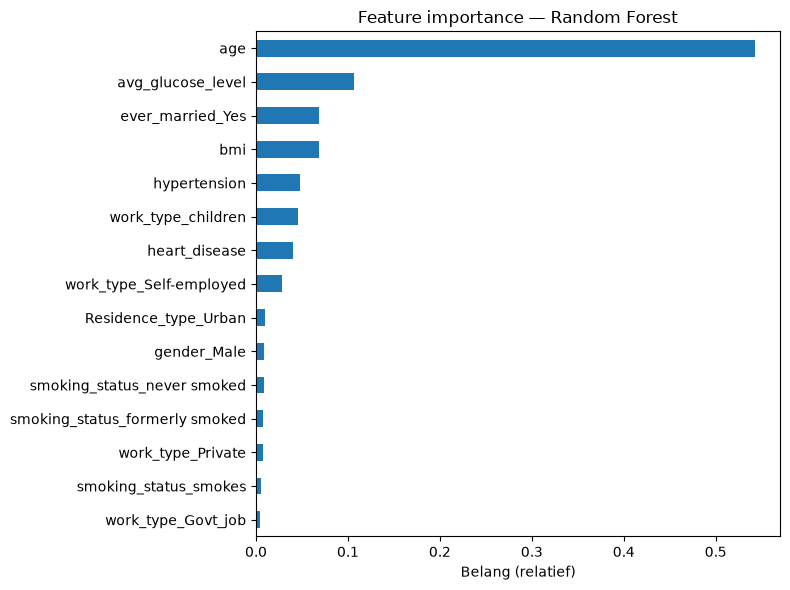

age                               0.543
avg_glucose_level                 0.107
ever_married_Yes                  0.069
bmi                               0.068
hypertension                      0.048
work_type_children                0.046
heart_disease                     0.040
work_type_Self-employed           0.028
Residence_type_Urban              0.009
gender_Male                       0.009
smoking_status_never smoked       0.009
smoking_status_formerly smoked    0.007
work_type_Private                 0.007
smoking_status_smokes             0.005
work_type_Govt_job                0.004
dtype: float64

In [39]:
rf_best.fit(X, y)

importances = pd.Series(
    rf_best.feature_importances_, index=X.columns
).sort_values()

importances.plot(kind="barh", figsize=(8, 6))
plt.title("Feature importance — Random Forest")
plt.xlabel("Belang (relatief)")
plt.tight_layout()
plt.show()

importances.sort_values(ascending=False).round(3)

**Observatie:**
- `age` is veruit de belangrijkste feature (0,543). Dit komt overeen met de EDA (paragraaf 4.6).
- `avg_glucose_level` staat op de tweede plaats (0,107). Een boom kan splitsen op een zeer hoge waarde en pikt dit niet-lineaire verband dus op.
- `ever_married_Yes` staat op de derde plaats. Deze feature hangt sterk samen met leeftijd (paragraaf 4.5.2) en wordt door de bomen gebruikt als vervanger voor leeftijd. Feature importance corrigeert niet voor confounders.
- `heart_disease` en `hypertension` scoren lager dan verwacht op basis van de EDA. Binaire features hebben maar één mogelijke split en gelden voor een kleine groep patiënten. Numerieke features hebben veel meer mogelijke splits en krijgen daardoor een hogere importance. Dit is een bekende vertekening.

**Voor de arts:** feature importance laat zien hoe vaak het model een feature gebruikt, maar niet in welke richting of waarom. De uitkomst moet daarom met voorzichtigheid worden gelezen.

#### Kaggle-submissions

Voor Logistic Regression en het voting ensemble hebben we al een submission gemaakt. Om de modellen ook op Kaggle te kunnen vergelijken, maken we voor elk ensemble-model een eigen submission. We gebruiken steeds dezelfde aanpak: het model wordt op alle trainingsdata getraind, de threshold wordt met 5-fold cross-validatie gekozen op F1 en daarna voorspellen we de testset.

We beginnen met het Random Forest met `min_samples_leaf=50` en class weights.

In [40]:
rf_final = TunedThresholdClassifierCV(
    rf_best, scoring="f1", cv=5, random_state=RANDOM_STATE
)
rf_final.fit(X, y)

test_pred = rf_final.predict(X_test)

submission = pd.DataFrame({"id": test_ids, TARGET: test_pred})
submission.to_csv(SUBMISSION_DIR / "random_forest.csv", index=False)

print("Gekozen threshold:", round(float(rf_final.best_threshold_), 2))
print("Aantal voorspelde herseninfarcten:", test_pred.sum(), f"({test_pred.mean() * 100:.2f}%)")

Gekozen threshold: 0.71
Aantal voorspelde herseninfarcten: 794 (9.47%)


**Observatie:** de gekozen threshold is 0,71, wat past bij de waarden uit de cross-validatie (0,70–0,75). Het model voorspelt bij 794 patiënten (9,47%) een herseninfarct, terwijl in de trainingsdata maar 1,54% een herseninfarct heeft. Het grootste deel van deze voorspellingen is dus een vals alarm. Dat past bij de lage precision (ongeveer 0,08) die we eerder zagen: het model accepteert veel valse alarmen om genoeg echte gevallen te vinden.

Daarna het Gradient Boosting-model. Dit model heeft geen class weights, dus de threshold moet hier het hele werk doen. We verwachten daarom een veel lagere threshold dan bij het Random Forest.

In [41]:
gb_final = TunedThresholdClassifierCV(
    gb, scoring="f1", cv=5, random_state=RANDOM_STATE
)
gb_final.fit(X, y)

test_pred = gb_final.predict(X_test)

submission = pd.DataFrame({"id": test_ids, TARGET: test_pred})
submission.to_csv(SUBMISSION_DIR / "gradient_boosting.csv", index=False)

print("Gekozen threshold:", round(float(gb_final.best_threshold_), 2))
print("Aantal voorspelde herseninfarcten:", test_pred.sum(), f"({test_pred.mean() * 100:.2f}%)")

Gekozen threshold: 0.06
Aantal voorspelde herseninfarcten: 594 (7.08%)


**Observatie:** de gekozen threshold is 0,06 en het model voorspelt bij 594 patiënten (7,08%) een herseninfarct. De threshold ligt veel lager dan bij het Random Forest, omdat dit model geen class weights gebruikt en de voorspelde kansen daardoor klein blijven.

Op Kaggle scoort het Random Forest een F1 van 0,099 en Gradient Boosting 0,081. Ter vergelijking: Logistic Regression haalt 0,094 en het voting ensemble 0,093. De scores op Kaggle liggen lager dan in de cross-validatie (ongeveer 0,14). De public score wordt berekend op een deel van de testset met weinig herseninfarcten, waardoor de score sterk kan schommelen.

Als laatste XGBoost. We gebruiken de eenvoudigere variant (200 bomen, diepte 3, learning rate 0,05), omdat die in de cross-validatie beter scoorde dan de standaardinstellingen.

In [42]:
xgb_final = TunedThresholdClassifierCV(
    xgb_models["eenvoudiger"], scoring="f1", cv=5, random_state=RANDOM_STATE
)
xgb_final.fit(X, y)

test_pred = xgb_final.predict(X_test)

submission = pd.DataFrame({"id": test_ids, TARGET: test_pred})
submission.to_csv(SUBMISSION_DIR / "xgboost.csv", index=False)

print("Gekozen threshold:", round(float(xgb_final.best_threshold_), 2))
print("Aantal voorspelde herseninfarcten:", test_pred.sum(), f"({test_pred.mean() * 100:.2f}%)")

Gekozen threshold: 0.06
Aantal voorspelde herseninfarcten: 596 (7.11%)


**Observatie:** de gekozen threshold is 0,06 en het model voorspelt bij 653 patiënten (7,78%) een herseninfarct. Op Kaggle haalt XGBoost een F1 van 0,079, de laagste score van onze ensemble-modellen.

| Model | F1 cross-validatie | F1 Kaggle (public) |
|---|---|---|
| Random Forest | 0,135 | 0,099 |
| Logistic Regression | 0,143 | 0,094 |
| Voting ensemble | 0,142 | 0,093 |
| Gradient Boosting | 0,135 | 0,081 |
| XGBoost | 0,139 | 0,079 |

In de cross-validatie liggen de modellen dicht bij elkaar, maar op Kaggle scoren de modellen met class weights (Random Forest, Logistic Regression en het voting ensemble) duidelijk beter dan de boosting-modellen zonder class weights. Alle scores op Kaggle liggen lager dan in de cross-validatie.

### 6.7 Zelf samengesteld ensemble

We combineren drie verschillende modellen met een `VotingClassifier`: de logistic regression uit paragraaf 6.3, en het Random Forest en XGBoost uit paragraaf 6.6. Bij **soft voting** wordt het gemiddelde genomen van de voorspelde kansen van de drie modellen.

Een ensemble werkt het best als de modellen verschillende soorten fouten maken. Logistic regression legt lineaire verbanden, de boommodellen kunnen niet-lineaire verbanden en interacties oppikken.

Om de kansen te kunnen middelen moeten ze op dezelfde schaal liggen. Daarom gebruiken alle drie de modellen class weights. Bij XGBoost heet dit `scale_pos_weight`: de verhouding tussen het aantal patiënten zonder en met een herseninfarct.

In [43]:
# Prompt 7: Zelf samengesteld soft-voting ensemble

scale_pos_weight = (y == 0).sum() / (y == 1).sum()
xgb_best = XGBClassifier(
    n_estimators=200, max_depth=3, learning_rate=0.05,
    scale_pos_weight=scale_pos_weight, random_state=RANDOM_STATE, n_jobs=-1,
)

voting = VotingClassifier(
    [("logreg", balanced), ("rf", rf_best), ("xgb", xgb_best)],
    voting="soft",
)
voting_tuned = TunedThresholdClassifierCV(
    voting, scoring="f1", cv=5, random_state=RANDOM_STATE
)

scores = cross_validate(voting_tuned, X, y, cv=cv, scoring=scoring,
                        return_estimator=True)
for metric in scoring:
    print(f"{metric}: {scores[f'test_{metric}'].mean():.3f}")
print("Gekozen thresholds:",
      [round(float(m.best_threshold_), 2) for m in scores["estimator"]])
print("scale_pos_weight:", round(scale_pos_weight, 1))

accuracy: 0.924
precision: 0.088
recall: 0.410
f1: 0.142
Gekozen thresholds: [0.78, 0.78, 0.75, 0.74, 0.81]
scale_pos_weight: 63.9


[ChatGPT, 2026, Prompt 7: Zelf samengesteld soft-voting ensemble](https://chatgpt.com/share/6ac29041-74c8-83eb-b40b-540d3a5bef38)

**Observatie:** het ensemble haalt een F1-score van 0,142 (precision 0,088, recall 0,410). Dat is beter dan het Random Forest (0,135) en XGBoost (0,139) afzonderlijk, maar de winst is klein. De thresholds liggen tussen 0,74 en 0,81 en zijn dus stabiel.

Een ensemble levert winst op als de modellen verschillende fouten maken. Hier maken de drie modellen grotendeels dezelfde fouten: oudere patiënten met risicofactoren die toch geen herseninfarct krijgen. Het middelen van de kansen lost dat niet op. De beperking zit in de data, niet in het model: veel patiënten met dezelfde risicofactoren krijgen geen herseninfarct.

#### Kaggle-submission

Het zelf samengestelde ensemble scoort het hoogst van de ensembles (F1 0,142). We trainen dit model met de getunede threshold op de volledige trainset en voorspellen de testset.

In [44]:
voting_tuned.fit(X, y)
test_pred = voting_tuned.predict(X_test)

submission = pd.DataFrame({"id": test_ids, TARGET: test_pred})
SUBMISSION_DIR.mkdir(exist_ok=True)
submission.to_csv(SUBMISSION_DIR / "ensemble.csv", index=False)

print("Gekozen threshold:", round(float(voting_tuned.best_threshold_), 2))
print("Aantal voorspelde herseninfarcten:", test_pred.sum(),
      f"({test_pred.mean() * 100:.2f}%)")

Gekozen threshold: 0.77
Aantal voorspelde herseninfarcten: 652 (7.77%)


**Observatie:** op de volledige trainset wordt een threshold van 0,77 gekozen, binnen het bereik van de cross-validatie (0,74–0,81). Het ensemble wijst 652 van de 8.388 testpatiënten (7,77%) aan als risicopatiënt. Als de testset hetzelfde percentage herseninfarcten heeft als de trainset (1,54%, ongeveer 129 patiënten), zijn de meeste waarschuwingen vals alarm. Dit komt overeen met de precision van ongeveer 9% uit de cross-validatie.

#### Conclusie ensembles

| Model | Precision | Recall | F1-score |
|---|---|---|---|
| Random Forest (standaard) | 0,000 | 0,000 | 0,000 |
| Random Forest (`min_samples_leaf=50`, balanced) | 0,081 | 0,412 | 0,135 |
| Gradient Boosting | 0,079 | 0,474 | 0,135 |
| XGBoost (eenvoudiger) | 0,084 | 0,422 | 0,139 |
| Zelf samengesteld ensemble (voting) | 0,088 | 0,410 | **0,142** |

Alle scores zijn gemeten met 5-fold cross-validatie en een threshold die binnen elke fold is gekozen.

- **Onbalans:** geen enkel model lost de onbalans vanzelf op. Zonder aanpassingen voorspellen ook de ensembles voor (bijna) geen enkele patiënt een herseninfarct. Een afgestemde threshold is bij elk model nodig.
- **Overfitting:** eenvoudige bomen werken beter dan complexe. Bij het Random Forest was `min_samples_leaf` nodig om de class weights effect te geven, en XGBoost met ondiepe bomen scoort duidelijk beter (0,139) dan met de standaardinstellingen (0,096). Met slechts 517 patiënten met een herseninfarct leren complexe bomen toevallige patronen.
- **Class weights of threshold:** class weights met een hoge threshold (0,70–0,81) en geen class weights met een lage threshold (0,05) geven vrijwel dezelfde score. Het zijn twee manieren om hetzelfde te bereiken.
- **Beste ensemble:** het zelf samengestelde ensemble scoort het hoogst (0,142). De winst ten opzichte van de afzonderlijke modellen is klein: de modellen maken grotendeels dezelfde fouten, waardoor combineren weinig oplevert.
- **Plafond:** alle ensembles komen uit tussen 0,135 en 0,142. De verschillen zijn kleiner dan de spreiding tussen de folds. De beperking zit in de data: de beschikbare features bevatten te weinig informatie om patiënten mét en zonder herseninfarct goed te scheiden.

**Voor de arts:** ensembles zijn complexe modellen en minder goed uitlegbaar. Feature importance laat zien welke features het model gebruikt, maar niet waarom een individuele patiënt als risicopatiënt wordt aangewezen. De vergelijking met de andere modellen volgt in hoofdstuk 7.

---------
## 7. Conclusie en advies

### 7.1 Overzicht van de scores

### 7.2 Beste model

### 7.3 Overwegingen naast prestaties

### 7.4 Advies aan artsen

-----------
## 8. Referenties

- ChatGPT, 2026, Prompt 1: Cross-validatie en scoring bij een ongebalanceerde dataset. [https://chatgpt.com/share/6ac288d2-1638-83ed-a0f3-30b92d4f448a]

- ChatGPT, 2026, Prompt 2: Logistic Regression pipeline zonder data leakage. [https://chatgpt.com/share/6ac288d2-1638-83ed-a0f3-30b92d4f448a]

- ChatGPT, 2026, Prompt 3: Threshold tuning voor Logistic Regression [https://chatgpt.com/share/6ac288d2-1638-83ed-a0f3-30b92d4f448a]

- ChatGPT, 2026, Prompt 4: Hyperparameter tuning van Logistic Regression [https://chatgpt.com/share/6ac28d12-0404-83ed-9f48-af1214bd7174]

- ChatGPT, 2026, Prompt 5: Random Forest tuning met min_samples_leaf en threshold [https://chatgpt.com/share/6ac28ed6-c738-83eb-850d-9a7ad41ef408]

- ChatGPT, 2026, Prompt 6: Gradient Boosting met threshold tuning [https://chatgpt.com/share/6ac28f99-de3c-83ed-a7d1-426f0a5c3b9d]

- ChatGPT, 2026, Prompt 7: Zelf samengesteld soft-voting ensemble [https://chatgpt.com/share/6ac29041-74c8-83eb-b40b-540d3a5bef38]

**Data**

- Kaggle. (2026). *Predicting stroke 2026-27* [Competitie en dataset]. https://www.kaggle.com/competitions/predicting-stroke-2026-27
**Software**

- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., … Duchesnay, É. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830. https://jmlr.org/papers/v12/pedregosa11a.html
- Chen, T., & Guestrin, C. (2016). XGBoost: A Scalable Tree Boosting System. *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, 785–794. https://doi.org/10.1145/2939672.2939785